In [1]:
# imports and settings
import os, re, json, warnings
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import OneHotEncoder, StandardScaler, LabelEncoder
from sklearn.feature_selection import mutual_info_classif
from sklearn.ensemble import RandomForestClassifier
from sklearn.utils.class_weight import compute_class_weight
import joblib

warnings.filterwarnings('ignore')
os.makedirs('figures', exist_ok=True)
os.makedirs('processed', exist_ok=True)

SEED = 42
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'axes.titlesize': 12, 'axes.labelsize': 10, 'figure.dpi': 100})
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 220)

def show(name):
    plt.tight_layout()
    plt.savefig(f'figures/{name}.png', dpi=150, bbox_inches='tight')
    plt.show()

In [2]:
# load data
df = pd.read_csv('train.csv')
print('rows:', df.shape[0])
print('columns:', df.shape[1])
df.shape

rows: 20000
columns: 22


(20000, 22)

In [3]:
df.head(10)

,Location,Cross_Street,Latitude,Longitude,Date_Reported,Date_Occurred,Time_Occurred,Area_ID,Area_Name,Reporting_District_no,Part 1-2,Modus_Operandi,Victim_Age,Victim_Sex,Victim_Descent,Premise_Code,Premise_Description,Weapon_Used_Code,Weapon_Description,Status,Status_Description,Crime_Category
0,4500 CARPENTER AV,NaN,34.1522,-118.3910,03/09/2020 12:00:00 AM,03/06/2020 12:00:00 AM,1800.0,15.0,N Hollywood,1563.0,1.0,0385,75.0,M,W,101.0,STREET,NaN,NaN,IC,Invest Cont,Property Crimes
1,45TH ST,ALAMEDA ST,34.0028,-118.2391,02/27/2020 12:00:00 AM,02/27/2020 12:00:00 AM,1345.0,13.0,Newton,1367.0,1.0,0906 0352 0371 0446 1822 0344 0416 0417,41.0,M,H,216.0,SWAP MEET,400.0,"STRONG-ARM (HANDS, FIST, FEET OR BODILY FORCE)",IC,Invest Cont,Property Crimes
2,600 E MARTIN LUTHER KING JR BL,NaN,34.0111,-118.2653,08/21/2020 12:00:00 AM,08/21/2020 12:00:00 AM,605.0,13.0,Newton,1343.0,2.0,0329 1202,67.0,M,B,501.0,SINGLE FAMILY DWELLING,NaN,NaN,IC,Invest Cont,Property Crimes
3,14900 ORO GRANDE ST,NaN,34.2953,-118.4590,11/08/2020 12:00:00 AM,11/06/2020 12:00:00 AM,1800.0,19.0,Mission,1924.0,1.0,0329 1300,61.0,M,H,101.0,STREET,NaN,NaN,IC,Invest Cont,Property Crimes
4,7100 S VERMONT AV,NaN,33.9787,-118.2918,02/25/2020 12:00:00 AM,02/25/2020 12:00:00 AM,1130.0,12.0,77th Street,1245.0,1.0,0416 0945 1822 0400 0417 0344,0.0,X,X,401.0,MINI-MART,400.0,"STRONG-ARM (HANDS, FIST, FEET OR BODILY FORCE)",IC,Invest Cont,Property Crimes
5,300 N AVENUE 57,NaN,34.1127,-118.1942,01/10/2020 12:00:00 AM,01/10/2020 12:00:00 AM,256.0,11.0,Northeast,1118.0,2.0,0446 0416,50.0,M,H,502.0,"MULTI-UNIT DWELLING (APARTMENT, DUPLEX, ETC)",400.0,"STRONG-ARM (HANDS, FIST, FEET OR BODILY FORCE)",AO,Adult Other,Violent Crimes
6,1600 N SOTO ST,NaN,34.0623,-118.1980,08/17/2020 12:00:00 AM,08/17/2020 12:00:00 AM,1840.0,4.0,Hollenbeck,448.0,1.0,0325,0.0,X,X,202.0,LIQUOR STORE,NaN,NaN,IC,Invest Cont,Property Crimes
7,12600 BRADDOCK DR,NaN,33.9864,-118.4239,10/07/2021 12:00:00 AM,03/19/2020 12:00:00 AM,1100.0,14.0,Pacific,1455.0,1.0,1606 0344,68.0,F,W,502.0,"MULTI-UNIT DWELLING (APARTMENT, DUPLEX, ETC)",NaN,NaN,IC,Invest Cont,Property Crimes
8,5500 COLDWATER CA AV,NaN,34.1781,-118.4179,01/28/2020 12:00:00 AM,01/26/2020 12:00:00 AM,1600.0,9.0,Van Nuys,939.0,1.0,NaN,0.0,NaN,NaN,104.0,DRIVEWAY,NaN,NaN,IC,Invest Cont,Property Crimes
9,11500 AVIATION BL,NaN,33.9298,-118.3784,07/07/2020 12:00:00 AM,07/07/2020 12:00:00 AM,445.0,14.0,Pacific,1499.0,2.0,0329 1300 1402,22.0,F,H,108.0,PARKING LOT,NaN,NaN,AA,Adult Arrest,Property Crimes


In [4]:
df.tail(5)

,Location,Cross_Street,Latitude,Longitude,Date_Reported,Date_Occurred,Time_Occurred,Area_ID,Area_Name,Reporting_District_no,Part 1-2,Modus_Operandi,Victim_Age,Victim_Sex,Victim_Descent,Premise_Code,Premise_Description,Weapon_Used_Code,Weapon_Description,Status,Status_Description,Crime_Category
19995,5100 W ADAMS BL,NaN,34.0334,-118.3523,05/24/2020 12:00:00 AM,05/24/2020 12:00:00 AM,700.0,3.0,Southwest,303.0,2.0,0416 0446 2004 0913,51.0,M,H,501.0,SINGLE FAMILY DWELLING,400.0,"STRONG-ARM (HANDS, FIST, FEET OR BODILY FORCE)",IC,Invest Cont,Violent Crimes
19996,16900 ROSCOE BL,NaN,34.2212,-118.5011,12/25/2020 12:00:00 AM,12/25/2020 12:00:00 AM,259.0,10.0,West Valley,1008.0,1.0,1822 0209 0344 1414 1420,0.0,M,W,301.0,GAS STATION,NaN,NaN,IC,Invest Cont,Property Crimes
19997,1000 S SHENANDOAH ST,NaN,34.0571,-118.3815,09/25/2020 12:00:00 AM,09/25/2020 12:00:00 AM,1400.0,8.0,West LA,849.0,1.0,0344 1822 1420,42.0,M,H,102.0,SIDEWALK,NaN,NaN,IC,Invest Cont,Property Crimes
19998,300 W SEPULVEDA ST,NaN,33.7451,-118.2835,06/10/2020 12:00:00 AM,06/10/2020 12:00:00 AM,600.0,5.0,Harbor,558.0,2.0,1202 2038 0913 0602 1242 0553,76.0,F,H,501.0,SINGLE FAMILY DWELLING,NaN,NaN,IC,Invest Cont,Crimes against Public Order
19999,DALTON AV,VERNON AV,34.0037,-118.3034,02/18/2020 12:00:00 AM,02/17/2020 12:00:00 AM,1800.0,3.0,Southwest,397.0,1.0,NaN,0.0,NaN,NaN,101.0,STREET,NaN,NaN,IC,Invest Cont,Property Crimes


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 22 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Location               20000 non-null  object 
 1   Cross_Street           3448 non-null   object 
 2   Latitude               20000 non-null  float64
 3   Longitude              20000 non-null  float64
 4   Date_Reported          20000 non-null  object 
 5   Date_Occurred          20000 non-null  object 
 6   Time_Occurred          20000 non-null  float64
 7   Area_ID                20000 non-null  float64
 8   Area_Name              20000 non-null  object 
 9   Reporting_District_no  20000 non-null  float64
 10  Part 1-2               20000 non-null  float64
 11  Modus_Operandi         17259 non-null  object 
 12  Victim_Age             20000 non-null  float64
 13  Victim_Sex             17376 non-null  object 
 14  Victim_Descent         17376 non-null  object 
 15  Pr

In [6]:
# data dictionary (dataset in tabular form)
data_dict = pd.DataFrame({
    'column': df.columns,
    'dtype': df.dtypes.astype(str).values,
    'non_null': df.notna().sum().values,
    'missing_pct': (df.isna().mean() * 100).round(2).values,
    'unique': df.nunique().values,
    'example': [str(df[col].dropna().iloc[0]).strip()[:40] for col in df.columns],
})
data_dict.to_csv('processed/data_dictionary.csv', index=False)
data_dict

,column,dtype,non_null,missing_pct,unique,example
0,Location,object,20000,0.00,12399,4500 CARPENTER AV
1,Cross_Street,object,3448,82.76,1495,ALAMEDA ST
2,Latitude,float64,20000,0.00,3622,34.1522
3,Longitude,float64,20000,0.00,3578,-118.391
4,Date_Reported,object,20000,0.00,811,03/09/2020 12:00:00 AM
5,Date_Occurred,object,20000,0.00,366,03/06/2020 12:00:00 AM
6,Time_Occurred,float64,20000,0.00,996,1800.0
7,Area_ID,float64,20000,0.00,21,15.0
8,Area_Name,object,20000,0.00,21,N Hollywood
9,Reporting_District_no,float64,20000,0.00,1120,1563.0


In [7]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Latitude,20000.0,33.940704,2.126810,0.0000,34.0092,34.0587,34.165025,34.3281
Longitude,20000.0,-117.893072,7.377726,-118.6634,-118.4297,-118.3230,-118.274400,0.0000
Time_Occurred,20000.0,1352.380350,646.100291,1.0000,930.0000,1430.0000,1900.000000,2359.0000
Area_ID,20000.0,10.834250,6.033166,1.0000,6.0000,11.0000,16.000000,21.0000
Reporting_District_no,20000.0,1129.599200,603.330519,101.0000,632.0000,1162.0000,1622.000000,2197.0000
Part 1-2,20000.0,1.418150,0.493267,1.0000,1.0000,1.0000,2.000000,2.0000
Victim_Age,20000.0,30.135000,21.863645,-2.0000,12.0000,31.0000,46.000000,99.0000
Premise_Code,20000.0,297.176950,212.007298,101.0000,101.0000,203.0000,501.000000,969.0000
Weapon_Used_Code,7335.0,366.405044,120.485687,101.0000,312.0000,400.0000,400.000000,515.0000


In [8]:
df.describe(include='object').T

,count,unique,top,freq
Location,20000,12399,6TH,33
Cross_Street,3448,1495,BROADWAY,56
Date_Reported,20000,811,07/13/2020 12:00:00 AM,87
Date_Occurred,20000,366,01/01/2020 12:00:00 AM,137
Area_Name,20000,21,77th Street,1345
Modus_Operandi,17259,10489,0344,826
Victim_Sex,17376,4,M,8538
Victim_Descent,17376,17,H,6143
Premise_Description,19995,216,STREET,5033
Weapon_Description,7335,57,"STRONG-ARM (HANDS, FIST, FEET OR BODILY FORCE)",3990


In [9]:
num_cols_raw = df.select_dtypes('number').columns
shape_stats = pd.DataFrame({
    'skewness': df[num_cols_raw].skew(),
    'kurtosis': df[num_cols_raw].kurt(),
})
shape_stats.round(3)

,skewness,kurtosis
Latitude,-15.852,250.037
Longitude,15.915,251.378
Time_Occurred,-0.475,-0.717
Area_ID,-0.011,-1.179
Reporting_District_no,-0.004,-1.181
Part 1-2,0.332,-1.890
Victim_Age,0.115,-0.755
Premise_Code,0.541,-1.071
Weapon_Used_Code,-1.033,0.127


In [10]:
missing = pd.DataFrame({
    'missing': df.isna().sum(),
    'percent': (df.isna().mean() * 100).round(2),
}).sort_values('missing', ascending=False)
missing[missing.missing > 0]

,missing,percent
Cross_Street,16552,82.76
Weapon_Description,12665,63.32
Weapon_Used_Code,12665,63.32
Modus_Operandi,2741,13.70
Victim_Descent,2624,13.12
Victim_Sex,2624,13.12
Premise_Description,5,0.02


In [11]:
print('duplicate rows:', df.duplicated().sum())
print('victim age <= 0:', (df.Victim_Age <= 0).sum(), f'({(df.Victim_Age <= 0).mean():.1%})')
print('victim age < 0:', (df.Victim_Age < 0).sum())
print('latitude == 0:', (df.Latitude == 0).sum())
print('longitude == 0:', (df.Longitude == 0).sum())
print('victim sex == H:', (df.Victim_Sex == 'H').sum())
print('time occurred outside 0-2359:', ((df.Time_Occurred < 0) | (df.Time_Occurred > 2359)).sum())

duplicate rows: 13
victim age <= 0: 4834 (24.2%)
victim age < 0: 6
latitude == 0: 78
longitude == 0: 78
victim sex == H: 2
time occurred outside 0-2359: 0


In [12]:
# helper columns used only for exploration
fmt = '%m/%d/%Y %I:%M:%S %p'
eda = df.copy()
eda['date_occ'] = pd.to_datetime(eda.Date_Occurred, format=fmt)
eda['date_rep'] = pd.to_datetime(eda.Date_Reported, format=fmt)
eda['hour'] = (eda.Time_Occurred // 100).astype(int)
eda['dow'] = eda.date_occ.dt.day_name()
eda['month'] = eda.date_occ.dt.month
eda['report_lag'] = (eda.date_rep - eda.date_occ).dt.days
eda['age_clean'] = eda.Victim_Age.where(eda.Victim_Age > 0)
eda['has_weapon'] = eda.Weapon_Description.notna()
eda['has_victim'] = eda.Victim_Sex.notna()
eda['sex'] = eda.Victim_Sex.replace({'H': 'Unknown'}).fillna('Unknown')
eda['descent'] = eda.Victim_Descent.fillna('Unknown')
eda['valid_geo'] = (eda.Latitude != 0) & (eda.Longitude != 0)
eda['time_of_day'] = pd.cut(eda.hour, [-1, 5, 11, 17, 23],
                            labels=['Late night (0-5)', 'Morning (6-11)', 'Afternoon (12-17)', 'Evening (18-23)'])

def weapon_group(w):
    if pd.isna(w):
        return 'None recorded'
    w = w.upper()
    if 'STRONG-ARM' in w or 'PHYSICAL PRESENCE' in w:
        return 'Bodily force'
    if 'VERBAL' in w or 'DEMAND NOTE' in w or 'BOMB THREAT' in w:
        return 'Verbal threat'
    if re.search(r'SIMULATED GUN|TOY GUN|AIR PISTOL|STUN GUN|STARTER PISTOL', w):
        return 'Imitation or non-lethal'
    if re.search(r'GUN|PISTOL|REVOLVER|RIFLE|FIREARM|SHOTGUN|ASSAULT', w):
        return 'Firearm'
    if re.search(r'KNIFE|BLADE|CUTTING|MACHETE|AXE|SCISSORS|CLEAVER|SCREWDRIVER|ICE PICK', w):
        return 'Blade or sharp object'
    if re.search(r'CLUB|BAT|PIPE|STICK|HAMMER|BLUNT|BOARD|TIRE IRON|BRASS|CONCRETE|ROCK|BOTTLE|GLASS|BELT|FIXED OBJECT', w):
        return 'Blunt or thrown object'
    return 'Other'

eda['weapon_group'] = eda.Weapon_Description.apply(weapon_group)

cat_order = eda.Crime_Category.value_counts().index.tolist()
palette = dict(zip(cat_order, sns.color_palette('tab10', len(cat_order))))
dow_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

def rowpct_heat(index_series, title, ylabel, name, figsize=(9, 6), top=None):
    ct = pd.crosstab(index_series, eda.Crime_Category, normalize='index')[cat_order]
    if top is not None:
        ct = ct.loc[index_series.value_counts().head(top).index]
    plt.figure(figsize=figsize)
    sns.heatmap(ct, annot=True, fmt='.2f', cmap='Blues', cbar_kws={'label': 'share of row'})
    plt.title(title)
    plt.xlabel('Crime category')
    plt.ylabel(ylabel)
    plt.xticks(rotation=30, ha='right')
    show(name)

print(eda.weapon_group.value_counts())
print('report lag > 365 days:', (eda.report_lag > 365).sum())

weapon_group
None recorded              12665
Bodily force                4008
Other                        981
Firearm                      748
Verbal threat                549
Blade or sharp object        526
Blunt or thrown object       434
Imitation or non-lethal       89
Name: count, dtype: int64
report lag > 365 days: 382


In [13]:
# target distribution
vc = eda.Crime_Category.value_counts()
target_table = pd.DataFrame({'count': vc, 'percent': (vc / len(eda) * 100).round(2)})
print('majority class baseline accuracy:', round(vc.iloc[0] / len(eda), 4))
print('imbalance ratio (largest / smallest):', round(vc.iloc[0] / vc.iloc[-1], 1))
target_table

majority class baseline accuracy: 0.5833
imbalance ratio (largest / smallest): 65.2


,count,percent
Crime_Category,,
Property Crimes,11666,58.33
Violent Crimes,4767,23.84
Crimes against Public Order,1808,9.04
Fraud and White-Collar Crimes,1355,6.78
Crimes against Persons,225,1.12
Other Crimes,179,0.90


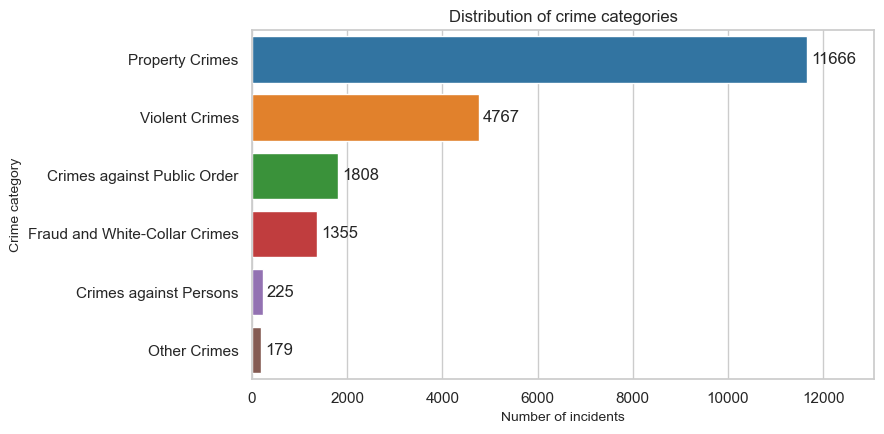

In [14]:
# figure 1: class distribution
plt.figure(figsize=(9, 4.5))
ax = sns.countplot(data=eda, y='Crime_Category', order=cat_order, hue='Crime_Category', palette=palette, legend=False)
for cont in ax.containers:
    ax.bar_label(cont, padding=3)
ax.set_xlim(0, vc.max() * 1.12)
plt.title('Distribution of crime categories')
plt.xlabel('Number of incidents')
plt.ylabel('Crime category')
show('fig01_target_distribution')

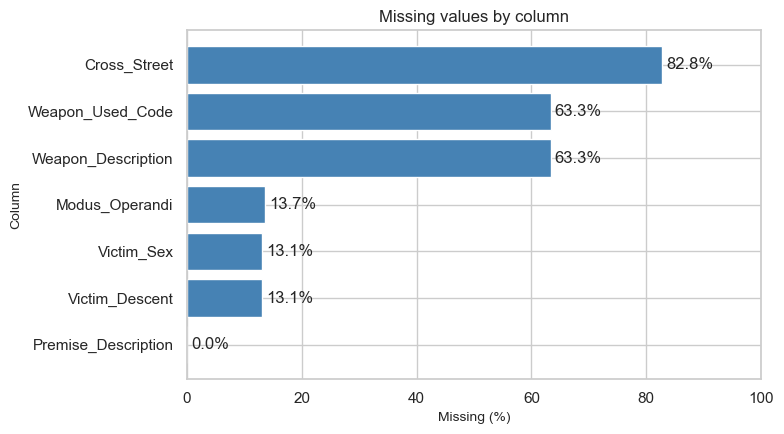

In [15]:
# figure 2: missing values per column
m = missing[missing.missing > 0].sort_values('percent')
plt.figure(figsize=(8, 4.5))
ax = plt.barh(m.index, m.percent, color='steelblue')
plt.bar_label(ax, fmt='%.1f%%', padding=3)
plt.xlim(0, 100)
plt.title('Missing values by column')
plt.xlabel('Missing (%)')
plt.ylabel('Column')
show('fig02_missing_values')

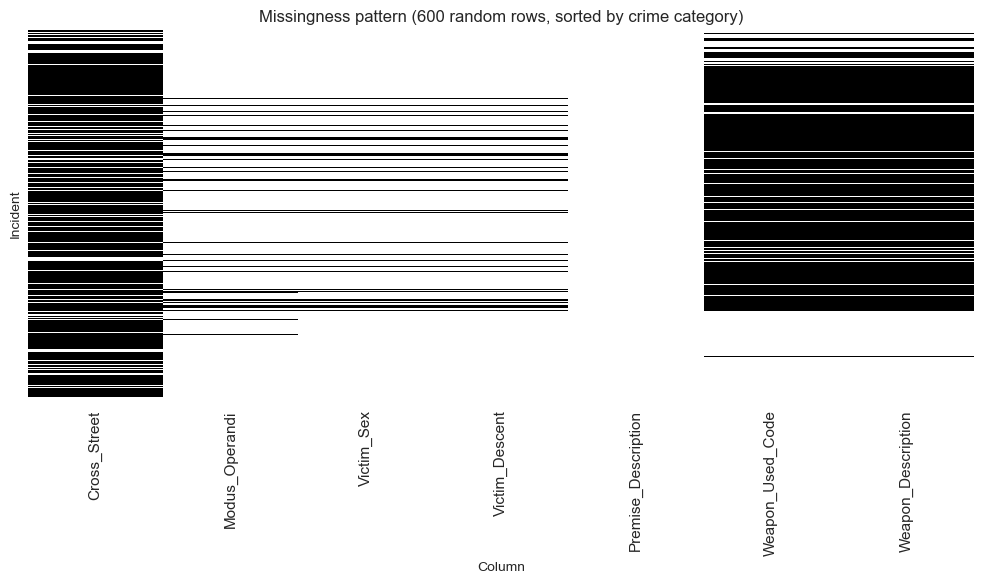

In [16]:
# figure 3: missingness pattern, rows sorted by crime category
cols_m = [col for col in df.columns if df[col].isna().any()]
samp = eda.sample(600, random_state=SEED).sort_values('Crime_Category')
plt.figure(figsize=(10, 6))
sns.heatmap(samp[cols_m].isna(), cbar=False, cmap='Greys', yticklabels=False)
plt.title('Missingness pattern (600 random rows, sorted by crime category)')
plt.xlabel('Column')
plt.ylabel('Incident')
show('fig03_missing_pattern')

In [17]:
# missing rate per category for the columns that matter
miss_by_cat = pd.DataFrame({
    'no_weapon_pct': (~eda.has_weapon).groupby(eda.Crime_Category).mean() * 100,
    'no_victim_pct': (~eda.has_victim).groupby(eda.Crime_Category).mean() * 100,
    'no_MO_pct': eda.Modus_Operandi.isna().groupby(eda.Crime_Category).mean() * 100,
    'no_cross_street_pct': eda.Cross_Street.isna().groupby(eda.Crime_Category).mean() * 100,
}).loc[cat_order].round(1)
miss_by_cat

,no_weapon_pct,no_victim_pct,no_MO_pct,no_cross_street_pct
Crime_Category,,,,
Property Crimes,87.3,22.2,22.5,82.5
Violent Crimes,0.6,0.0,0.2,77.2
Crimes against Public Order,49.9,0.0,1.9,88.2
Fraud and White-Collar Crimes,99.3,2.5,4.2,96.8
Crimes against Persons,20.9,0.0,2.2,92.4
Other Crimes,89.9,0.0,6.1,76.0


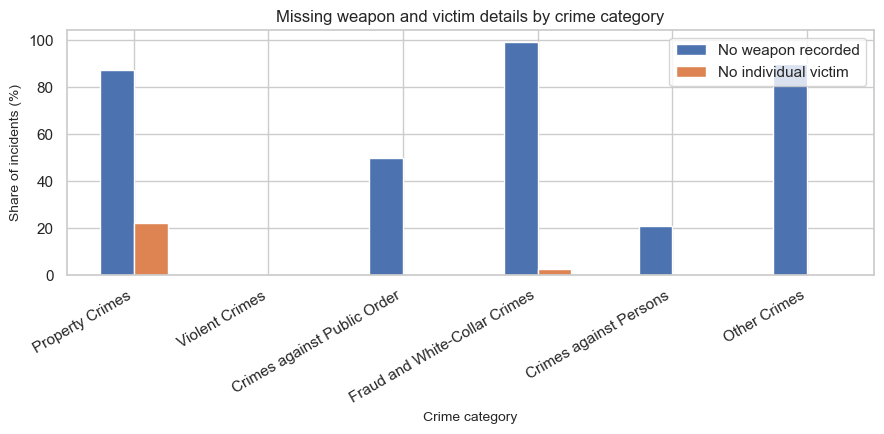

In [18]:
# figure 4: share of incidents with no weapon and no victim by category
tmp = miss_by_cat[['no_weapon_pct', 'no_victim_pct']].rename(
    columns={'no_weapon_pct': 'No weapon recorded', 'no_victim_pct': 'No individual victim'})
tmp.plot(kind='bar', figsize=(9, 4.5), color=['#4c72b0', '#dd8452'])
plt.title('Missing weapon and victim details by crime category')
plt.xlabel('Crime category')
plt.ylabel('Share of incidents (%)')
plt.xticks(rotation=30, ha='right')
show('fig04_missing_by_category')

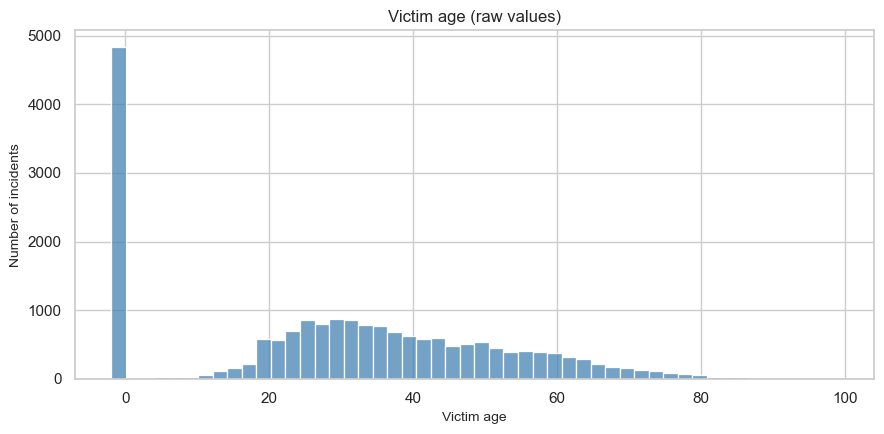

In [19]:
# figure 5: victim age, raw values
plt.figure(figsize=(9, 4.5))
sns.histplot(eda.Victim_Age, bins=50, color='steelblue')
plt.title('Victim age (raw values)')
plt.xlabel('Victim age')
plt.ylabel('Number of incidents')
show('fig05_age_raw')

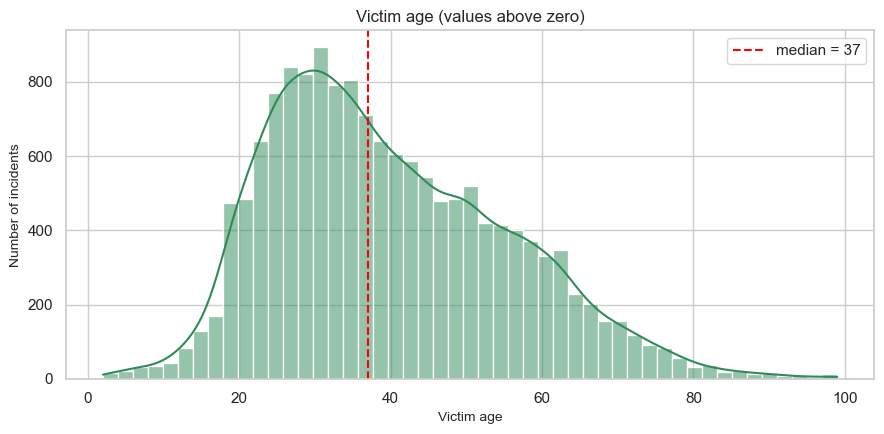

In [20]:
# figure 6: victim age after removing zero and negative values
plt.figure(figsize=(9, 4.5))
sns.histplot(eda.age_clean.dropna(), bins=49, kde=True, color='seagreen')
plt.axvline(eda.age_clean.median(), color='red', linestyle='--', label=f'median = {eda.age_clean.median():.0f}')
plt.title('Victim age (values above zero)')
plt.xlabel('Victim age')
plt.ylabel('Number of incidents')
plt.legend()
show('fig06_age_clean')

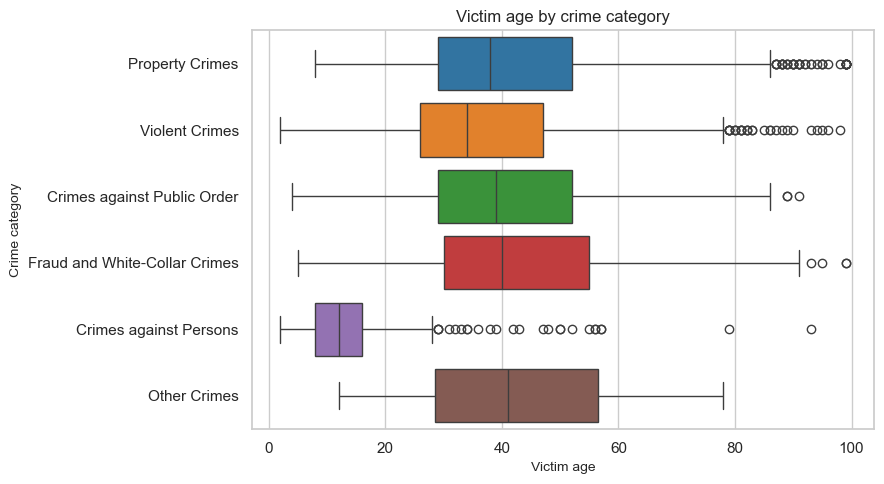

In [21]:
# figure 7: victim age by crime category
plt.figure(figsize=(9, 5))
sns.boxplot(data=eda, x='age_clean', y='Crime_Category', order=cat_order,
            hue='Crime_Category', palette=palette, legend=False)
plt.title('Victim age by crime category')
plt.xlabel('Victim age')
plt.ylabel('Crime category')
show('fig07_age_by_category')

In [22]:
age_summary = eda.groupby('Crime_Category').age_clean.describe().loc[cat_order].round(1)
age_summary

,count,mean,std,min,25%,50%,75%,max
Crime_Category,,,,,,,,
Property Crimes,7366.0,41.3,15.5,8.0,29.0,38.0,52.0,99.0
Violent Crimes,4621.0,37.1,14.9,2.0,26.0,34.0,47.0,98.0
Crimes against Public Order,1614.0,40.8,15.4,4.0,29.0,39.0,52.0,91.0
Fraud and White-Collar Crimes,1239.0,43.0,16.6,5.0,30.0,40.0,55.0,99.0
Crimes against Persons,215.0,15.2,13.2,2.0,8.0,12.0,16.0,93.0
Other Crimes,111.0,41.8,16.7,12.0,28.5,41.0,56.5,78.0


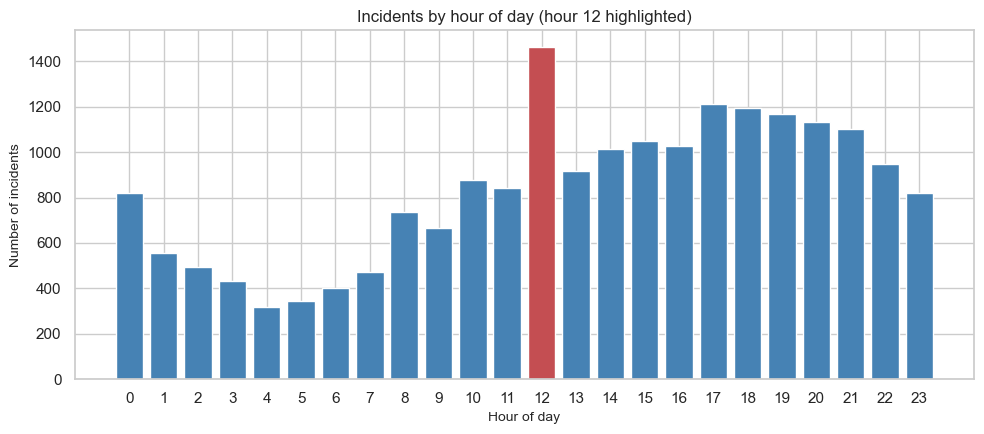

In [23]:
# figure 8: incidents by hour of day
plt.figure(figsize=(10, 4.5))
hc = eda.hour.value_counts().sort_index()
colors = ['#c44e52' if h == 12 else 'steelblue' for h in hc.index]
plt.bar(hc.index, hc.values, color=colors)
plt.xticks(range(24))
plt.title('Incidents by hour of day (hour 12 highlighted)')
plt.xlabel('Hour of day')
plt.ylabel('Number of incidents')
show('fig08_hour_distribution')

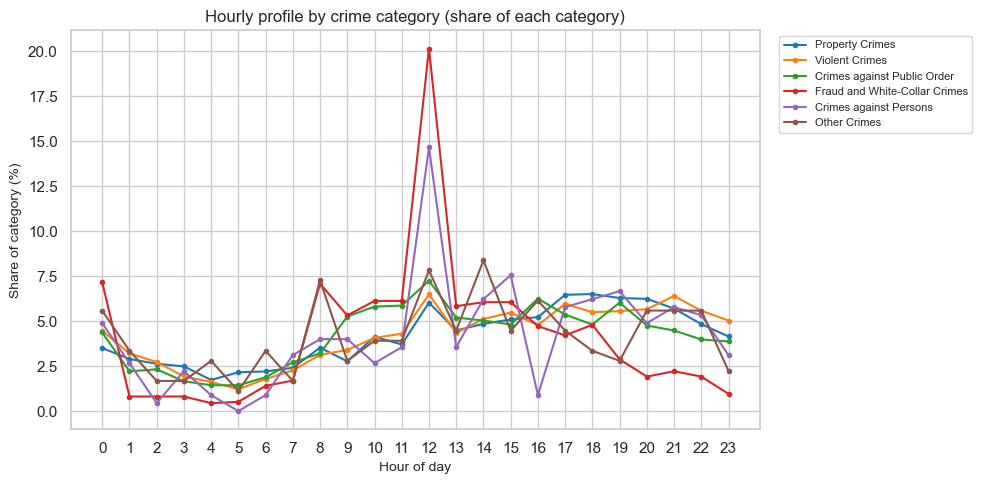

In [24]:
# figure 9: hourly profile of each crime category
share = pd.crosstab(eda.hour, eda.Crime_Category, normalize='columns')[cat_order] * 100
plt.figure(figsize=(10, 5))
for cat in cat_order:
    plt.plot(share.index, share[cat], marker='o', markersize=3, label=cat, color=palette[cat])
plt.xticks(range(24))
plt.title('Hourly profile by crime category (share of each category)')
plt.xlabel('Hour of day')
plt.ylabel('Share of category (%)')
plt.legend(fontsize=8, bbox_to_anchor=(1.02, 1), loc='upper left')
show('fig09_hour_by_category')

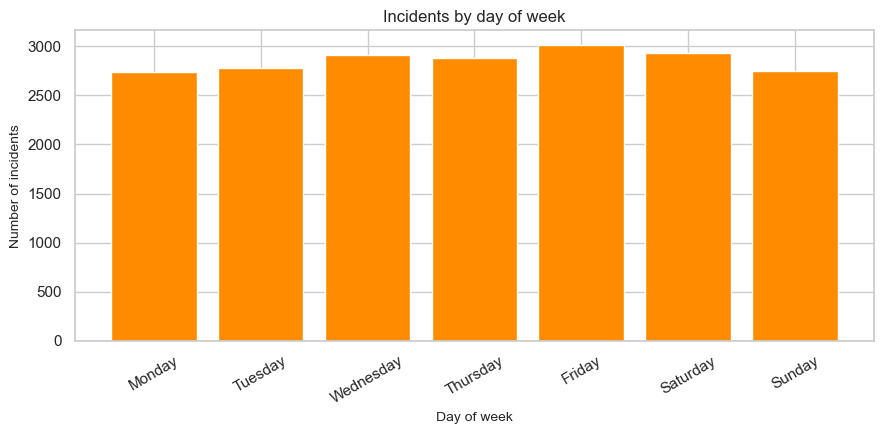

In [25]:
# figure 10: incidents by day of week
plt.figure(figsize=(9, 4.5))
dc = eda.dow.value_counts().reindex(dow_order)
plt.bar(dc.index, dc.values, color='darkorange')
plt.title('Incidents by day of week')
plt.xlabel('Day of week')
plt.ylabel('Number of incidents')
plt.xticks(rotation=30)
show('fig10_dayofweek')

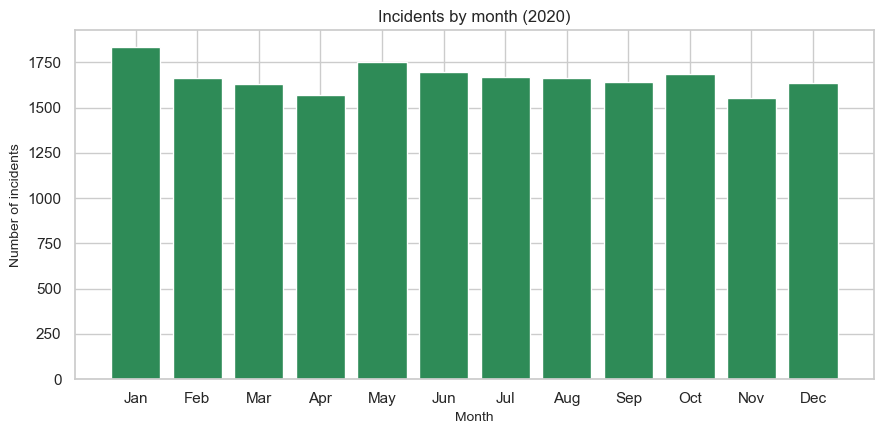

In [26]:
# figure 11: incidents by month
plt.figure(figsize=(9, 4.5))
mc = eda.month.value_counts().sort_index()
plt.bar(mc.index, mc.values, color='seagreen')
plt.xticks(range(1, 13), ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'])
plt.title('Incidents by month (2020)')
plt.xlabel('Month')
plt.ylabel('Number of incidents')
show('fig11_month')

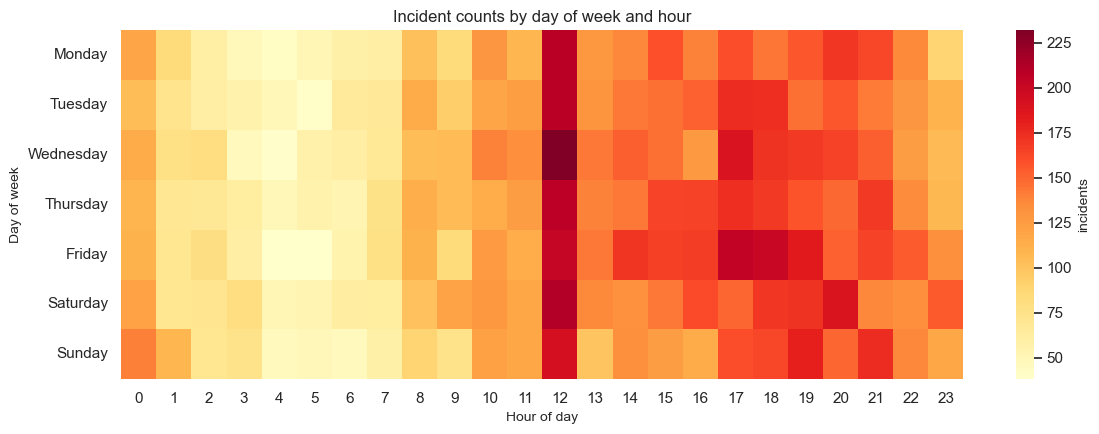

In [27]:
# figure 12: day of week by hour heatmap
pv = pd.crosstab(eda.dow, eda.hour).reindex(dow_order)
plt.figure(figsize=(12, 4.5))
sns.heatmap(pv, cmap='YlOrRd', cbar_kws={'label': 'incidents'})
plt.title('Incident counts by day of week and hour')
plt.xlabel('Hour of day')
plt.ylabel('Day of week')
show('fig12_dow_hour_heatmap')

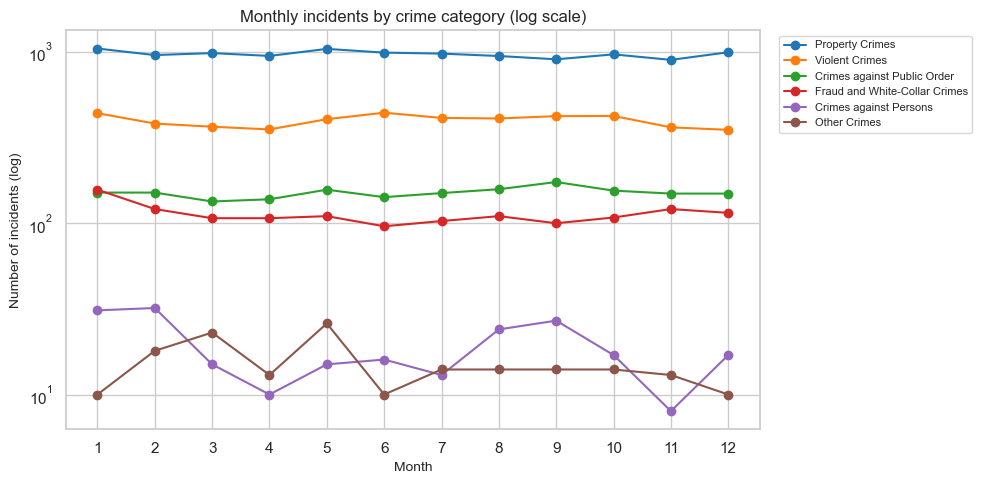

In [28]:
# figure 13: monthly counts by crime category (log scale)
mcat = pd.crosstab(eda.month, eda.Crime_Category)[cat_order]
plt.figure(figsize=(10, 5))
for cat in cat_order:
    plt.plot(mcat.index, mcat[cat], marker='o', label=cat, color=palette[cat])
plt.yscale('log')
plt.xticks(range(1, 13))
plt.title('Monthly incidents by crime category (log scale)')
plt.xlabel('Month')
plt.ylabel('Number of incidents (log)')
plt.legend(fontsize=8, bbox_to_anchor=(1.02, 1), loc='upper left')
show('fig13_month_by_category')

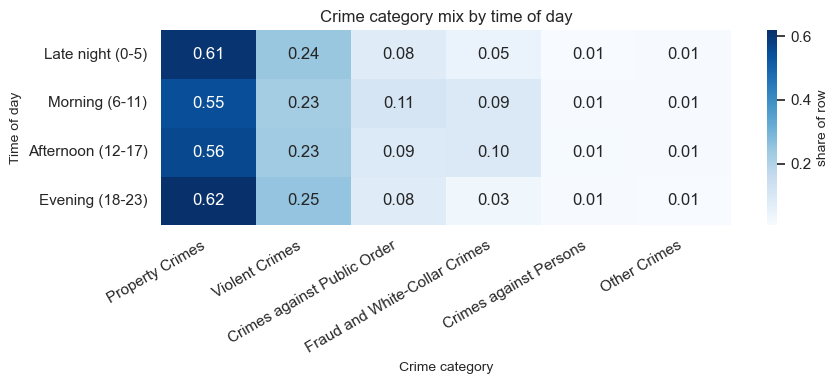

In [29]:
# figure 14: time of day by crime category
rowpct_heat(eda.time_of_day, 'Crime category mix by time of day', 'Time of day',
            'fig14_timeofday_by_category', figsize=(9, 4))

In [30]:
# report lag summary
print(eda.report_lag.describe().round(2))
print('reported same day:', f'{(eda.report_lag == 0).mean():.1%}')
print('reported within 7 days:', f'{(eda.report_lag <= 7).mean():.1%}')

count    20000.00
mean        22.12
std        116.42
min          0.00
25%          0.00
50%          0.00
75%          2.00
max       1437.00
Name: report_lag, dtype: float64
reported same day: 51.1%
reported within 7 days: 86.9%


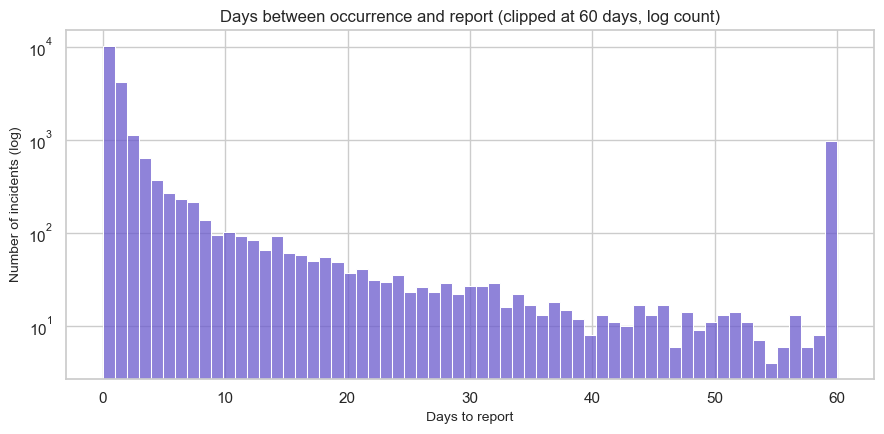

In [31]:
# figure 15: reporting delay (clipped at 60 days)
plt.figure(figsize=(9, 4.5))
sns.histplot(eda.report_lag.clip(upper=60), bins=61, color='slateblue')
plt.yscale('log')
plt.title('Days between occurrence and report (clipped at 60 days, log count)')
plt.xlabel('Days to report')
plt.ylabel('Number of incidents (log)')
show('fig15_report_lag')

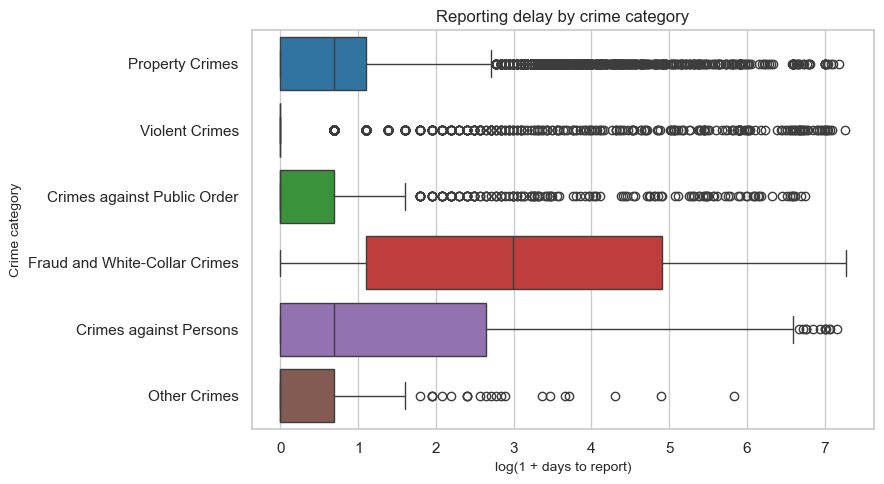

In [32]:
# figure 16: reporting delay by crime category
plt.figure(figsize=(9, 5))
sns.boxplot(x=np.log1p(eda.report_lag), y=eda.Crime_Category, order=cat_order,
            hue=eda.Crime_Category, palette=palette, legend=False)
plt.title('Reporting delay by crime category')
plt.xlabel('log(1 + days to report)')
plt.ylabel('Crime category')
show('fig16_report_lag_by_category')

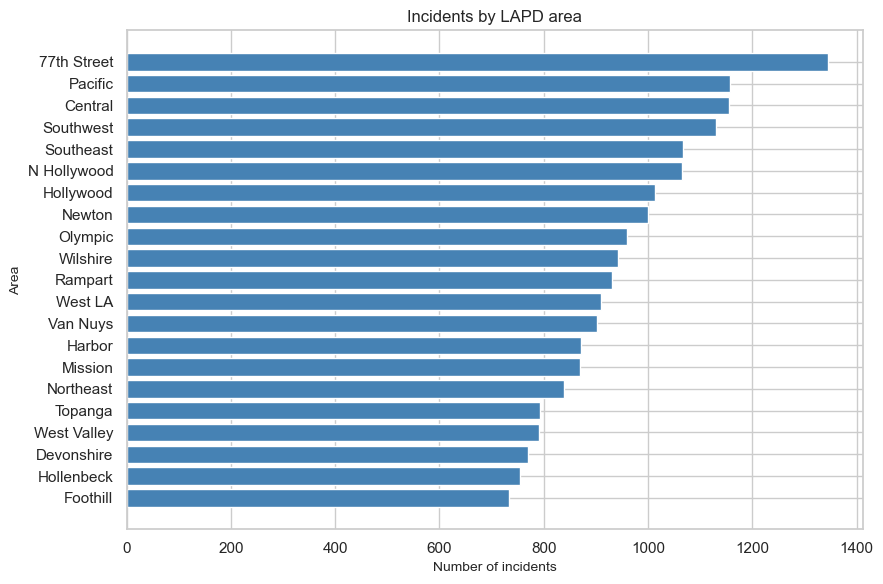

In [33]:
# figure 17: incidents per LAPD area
plt.figure(figsize=(9, 6))
ac = eda.Area_Name.value_counts()
plt.barh(ac.index[::-1], ac.values[::-1], color='steelblue')
plt.title('Incidents by LAPD area')
plt.xlabel('Number of incidents')
plt.ylabel('Area')
show('fig17_area_counts')

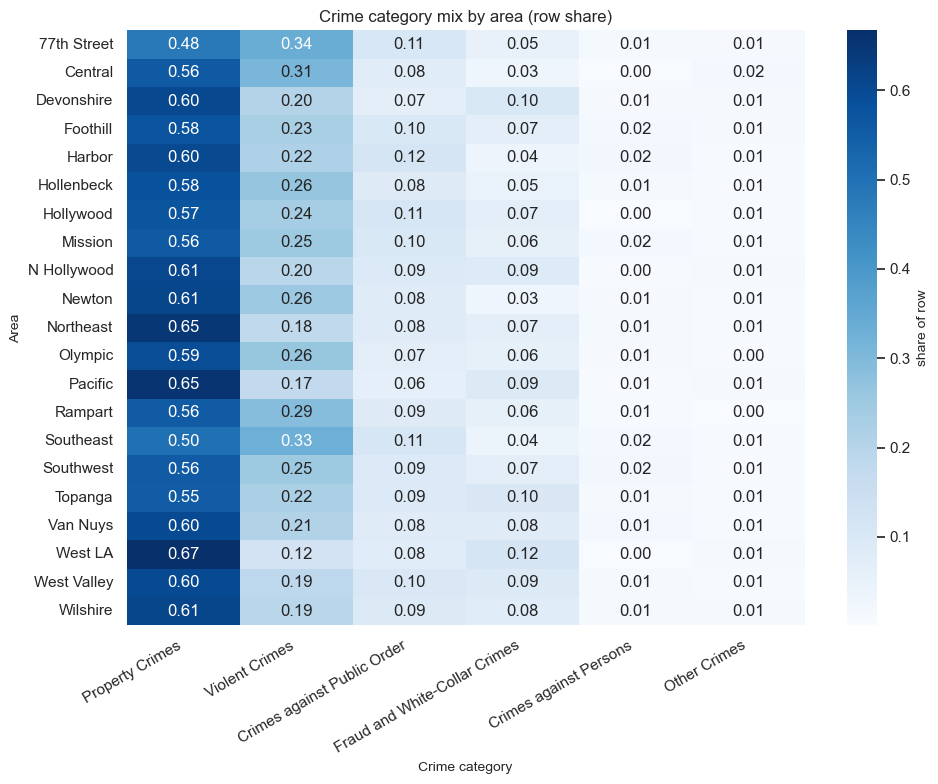

In [34]:
# figure 18: crime category mix by area
rowpct_heat(eda.Area_Name, 'Crime category mix by area (row share)', 'Area',
            'fig18_area_by_category', figsize=(10, 8))

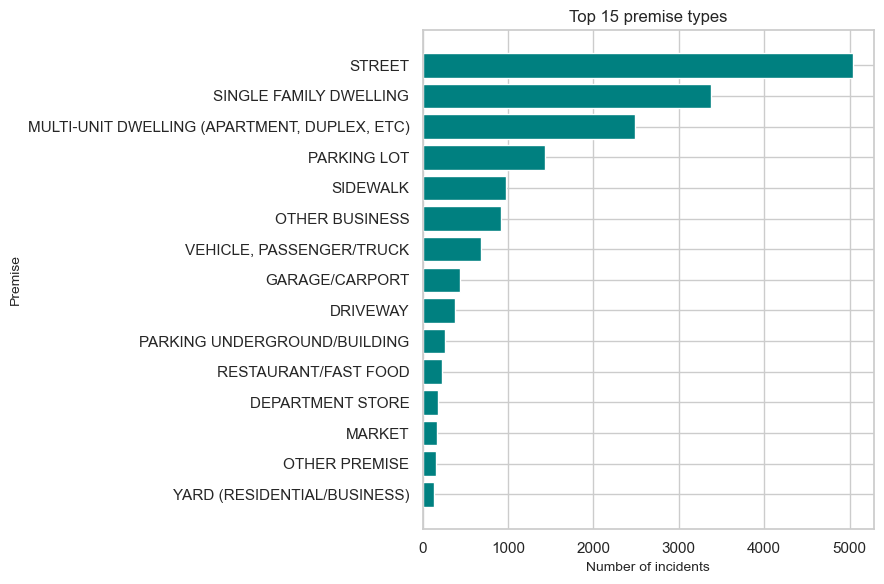

In [35]:
# figure 19: most common premises
plt.figure(figsize=(9, 6))
pc = eda.Premise_Description.value_counts().head(15)
plt.barh(pc.index[::-1], pc.values[::-1], color='teal')
plt.title('Top 15 premise types')
plt.xlabel('Number of incidents')
plt.ylabel('Premise')
show('fig19_top_premises')

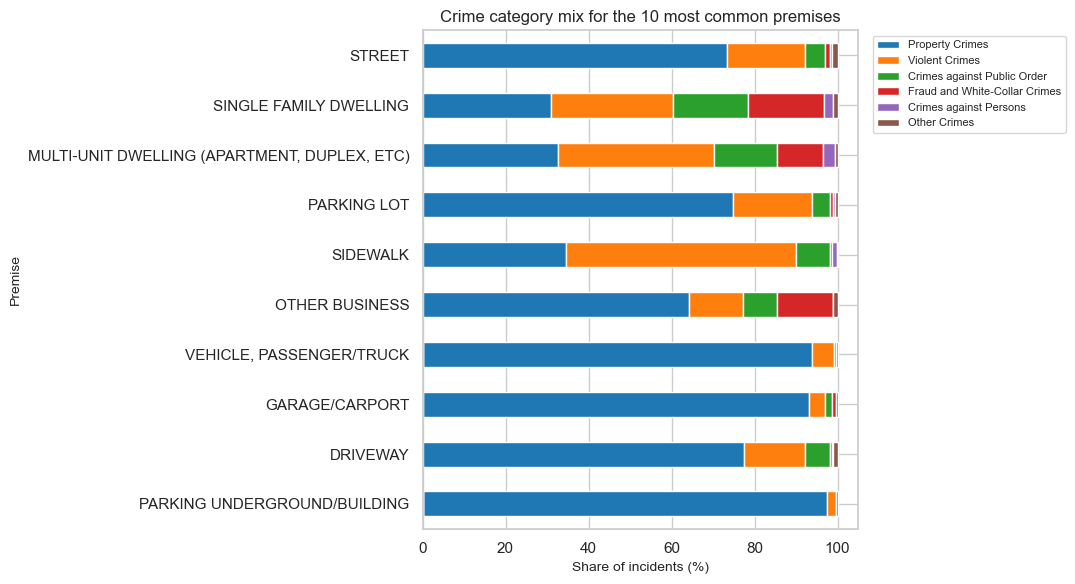

In [36]:
# figure 20: crime category mix for the top 10 premises
top_prem = eda.Premise_Description.value_counts().head(10).index
sub = eda[eda.Premise_Description.isin(top_prem)]
ct = (pd.crosstab(sub.Premise_Description, sub.Crime_Category, normalize='index')[cat_order] * 100).loc[top_prem[::-1]]
ct.plot(kind='barh', stacked=True, figsize=(11, 6), color=[palette[k] for k in cat_order])
plt.title('Crime category mix for the 10 most common premises')
plt.xlabel('Share of incidents (%)')
plt.ylabel('Premise')
plt.legend(fontsize=8, bbox_to_anchor=(1.02, 1), loc='upper left')
show('fig20_premise_by_category')

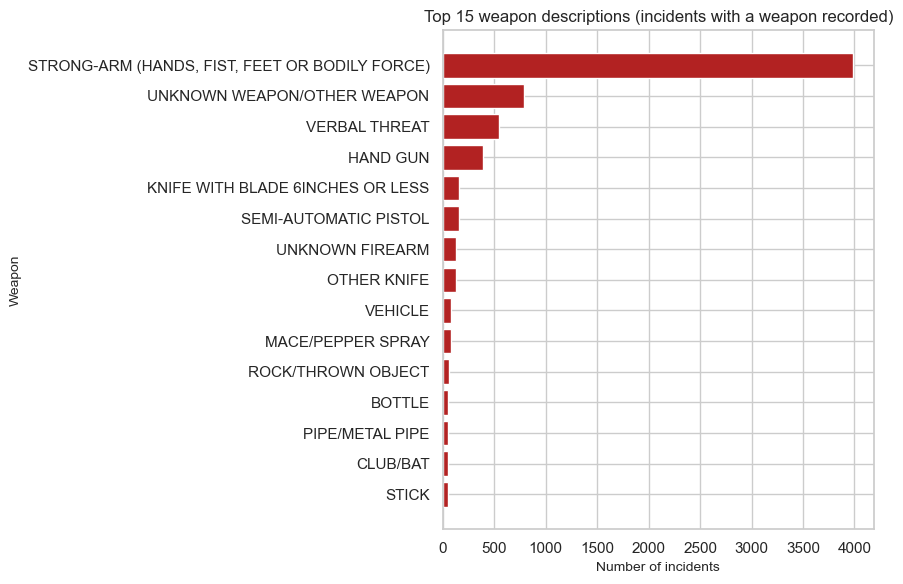

In [37]:
# figure 21: most common weapon descriptions
plt.figure(figsize=(9, 6))
wc = eda.Weapon_Description.value_counts().head(15)
plt.barh(wc.index[::-1], wc.values[::-1], color='firebrick')
plt.title('Top 15 weapon descriptions (incidents with a weapon recorded)')
plt.xlabel('Number of incidents')
plt.ylabel('Weapon')
show('fig21_top_weapons')

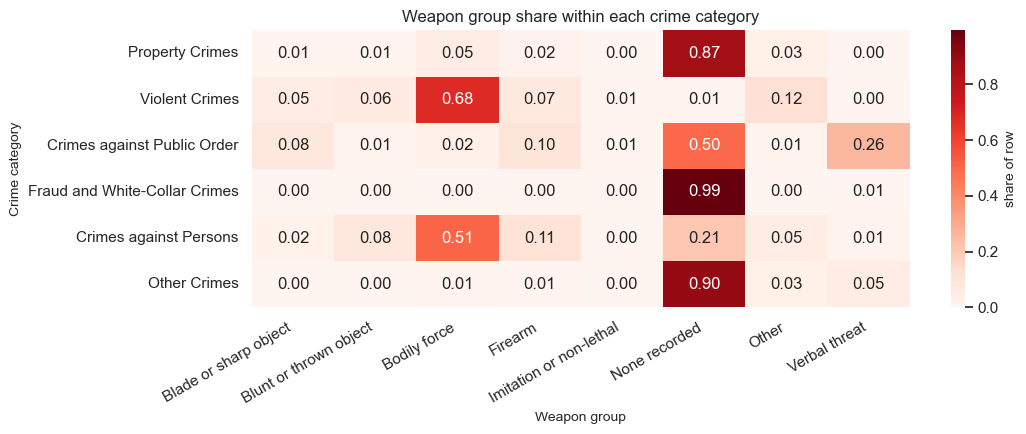

In [38]:
# figure 22: weapon group by crime category
wg = pd.crosstab(eda.Crime_Category, eda.weapon_group, normalize='index').loc[cat_order]
plt.figure(figsize=(11, 4.5))
sns.heatmap(wg, annot=True, fmt='.2f', cmap='Reds', cbar_kws={'label': 'share of row'})
plt.title('Weapon group share within each crime category')
plt.xlabel('Weapon group')
plt.ylabel('Crime category')
plt.xticks(rotation=30, ha='right')
show('fig22_weapon_group_by_category')

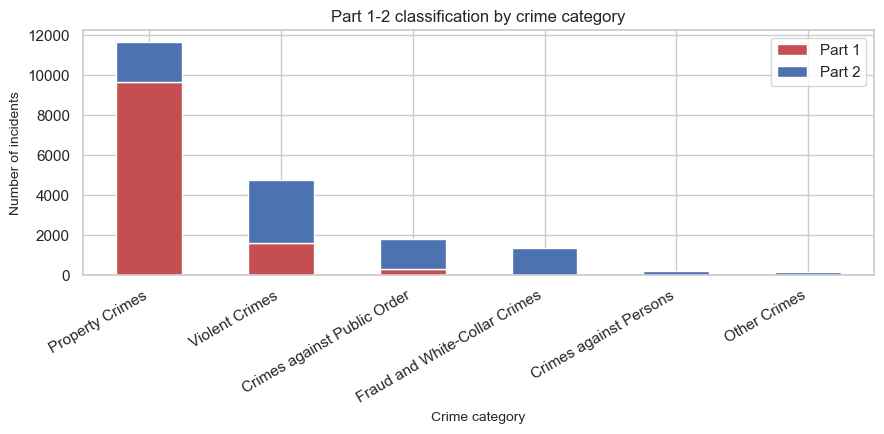

In [39]:
# figure 23: Part 1-2 classification by crime category
p12 = pd.crosstab(eda.Crime_Category, eda['Part 1-2']).loc[cat_order]
p12.columns = ['Part 1', 'Part 2']
p12.plot(kind='bar', stacked=True, figsize=(9, 4.5), color=['#c44e52', '#4c72b0'])
plt.title('Part 1-2 classification by crime category')
plt.xlabel('Crime category')
plt.ylabel('Number of incidents')
plt.xticks(rotation=30, ha='right')
show('fig23_part12_by_category')

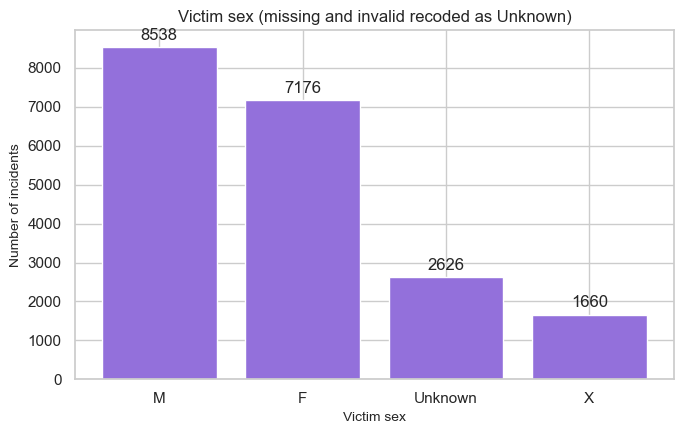

In [40]:
# figure 24: victim sex
plt.figure(figsize=(7, 4.5))
sc = eda.sex.value_counts()
ax = plt.bar(sc.index, sc.values, color='mediumpurple')
plt.bar_label(ax, padding=3)
plt.title('Victim sex (missing and invalid recoded as Unknown)')
plt.xlabel('Victim sex')
plt.ylabel('Number of incidents')
show('fig24_victim_sex')

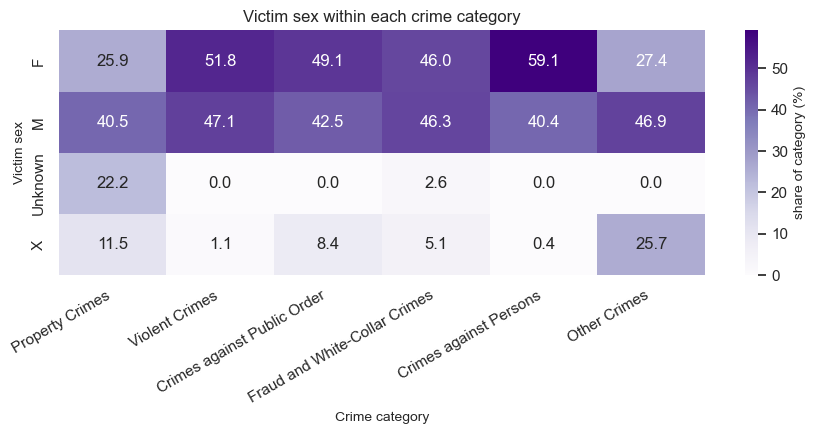

In [41]:
# figure 25: victim sex by crime category
ct = pd.crosstab(eda.sex, eda.Crime_Category, normalize='columns')[cat_order] * 100
plt.figure(figsize=(9, 4.5))
sns.heatmap(ct, annot=True, fmt='.1f', cmap='Purples', cbar_kws={'label': 'share of category (%)'})
plt.title('Victim sex within each crime category')
plt.xlabel('Crime category')
plt.ylabel('Victim sex')
plt.xticks(rotation=30, ha='right')
show('fig25_sex_by_category')

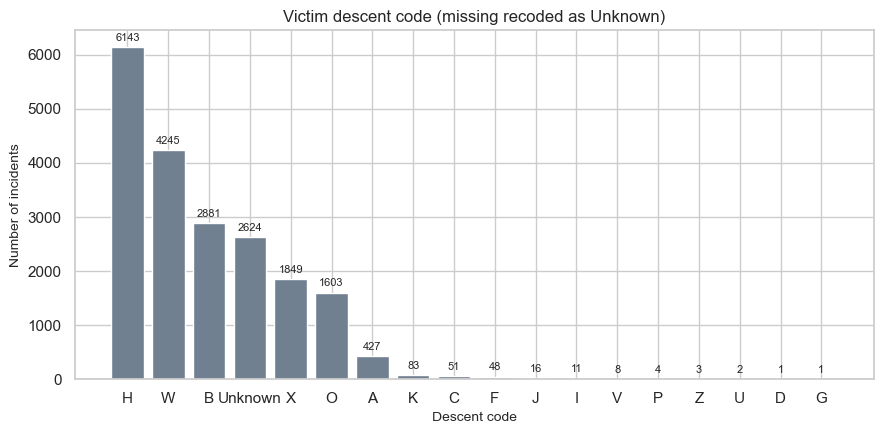

In [42]:
# figure 26: victim descent
plt.figure(figsize=(9, 4.5))
dcnt = eda.descent.value_counts()
ax = plt.bar(dcnt.index, dcnt.values, color='slategray')
plt.bar_label(ax, padding=3, fontsize=8)
plt.title('Victim descent code (missing recoded as Unknown)')
plt.xlabel('Descent code')
plt.ylabel('Number of incidents')
show('fig26_victim_descent')

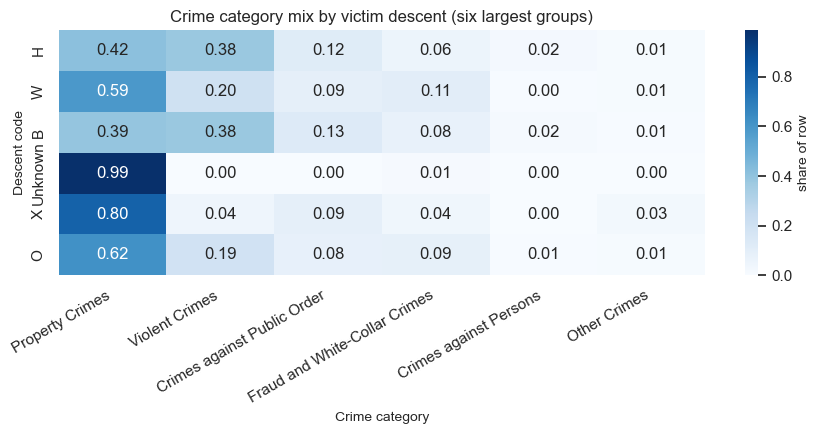

In [43]:
# figure 27: crime category mix for the six largest descent groups
top_d = eda.descent.value_counts().head(6).index
ct = pd.crosstab(eda.descent, eda.Crime_Category, normalize='index')[cat_order].loc[top_d]
plt.figure(figsize=(9, 4.5))
sns.heatmap(ct, annot=True, fmt='.2f', cmap='Blues', cbar_kws={'label': 'share of row'})
plt.title('Crime category mix by victim descent (six largest groups)')
plt.xlabel('Crime category')
plt.ylabel('Descent code')
plt.xticks(rotation=30, ha='right')
show('fig27_descent_by_category')

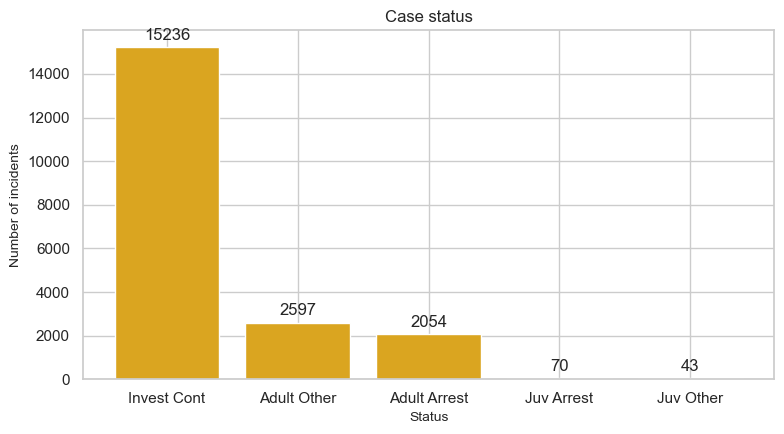

In [44]:
# figure 28: case status
plt.figure(figsize=(8, 4.5))
stc = eda.Status_Description.value_counts()
ax = plt.bar(stc.index, stc.values, color='goldenrod')
plt.bar_label(ax, padding=3)
plt.title('Case status')
plt.xlabel('Status')
plt.ylabel('Number of incidents')
show('fig28_status')

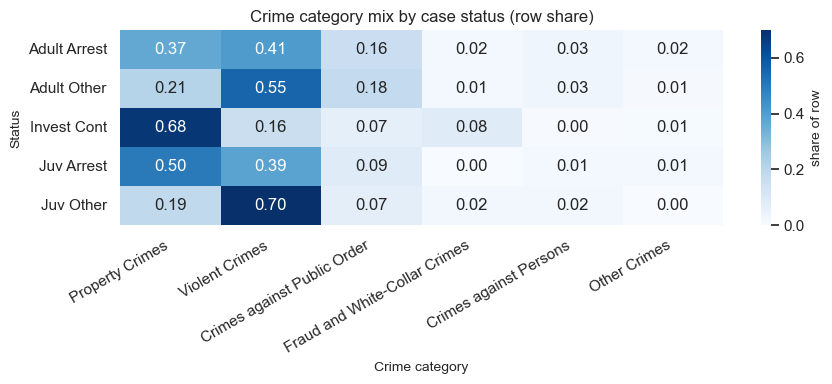

In [45]:
# figure 29: crime category mix by case status
rowpct_heat(eda.Status_Description, 'Crime category mix by case status (row share)', 'Status',
            'fig29_status_by_category', figsize=(9, 4))

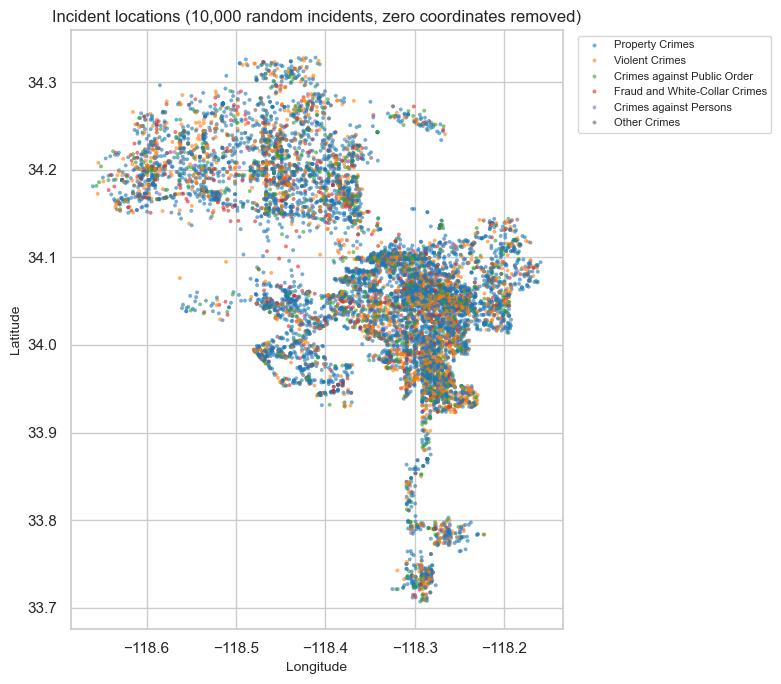

In [46]:
# figure 30: incident locations by category
geo = eda[eda.valid_geo].sample(10000, random_state=SEED)
plt.figure(figsize=(8, 7))
sns.scatterplot(data=geo, x='Longitude', y='Latitude', hue='Crime_Category',
                hue_order=cat_order, palette=palette, s=8, alpha=0.6, linewidth=0)
plt.title('Incident locations (10,000 random incidents, zero coordinates removed)')
plt.legend(fontsize=8, bbox_to_anchor=(1.02, 1), loc='upper left')
show('fig30_location_scatter')

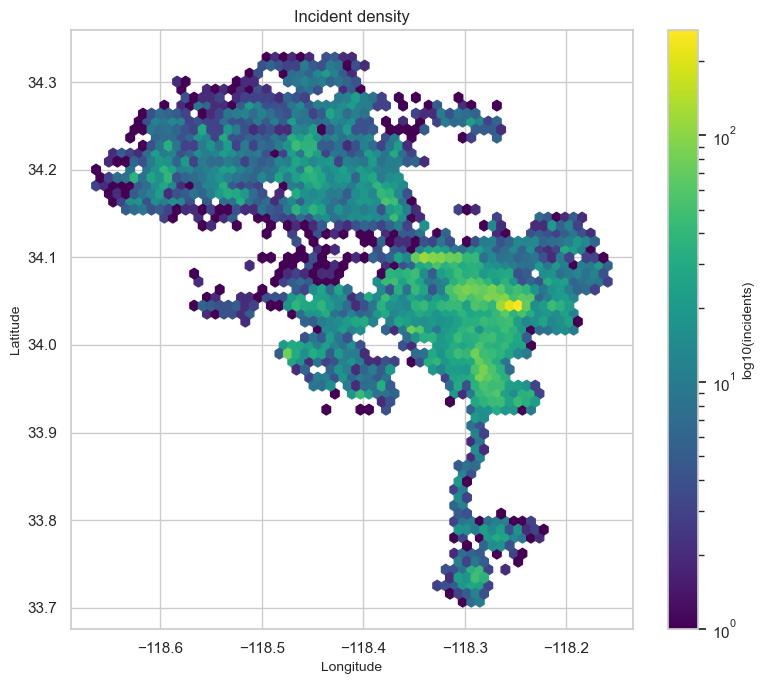

In [47]:
# figure 31: incident density
plt.figure(figsize=(8, 7))
v = eda[eda.valid_geo]
hb = plt.hexbin(v.Longitude, v.Latitude, gridsize=60, bins='log', mincnt=1, cmap='viridis')
plt.colorbar(hb, label='log10(incidents)')
plt.title('Incident density')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
show('fig31_location_density')

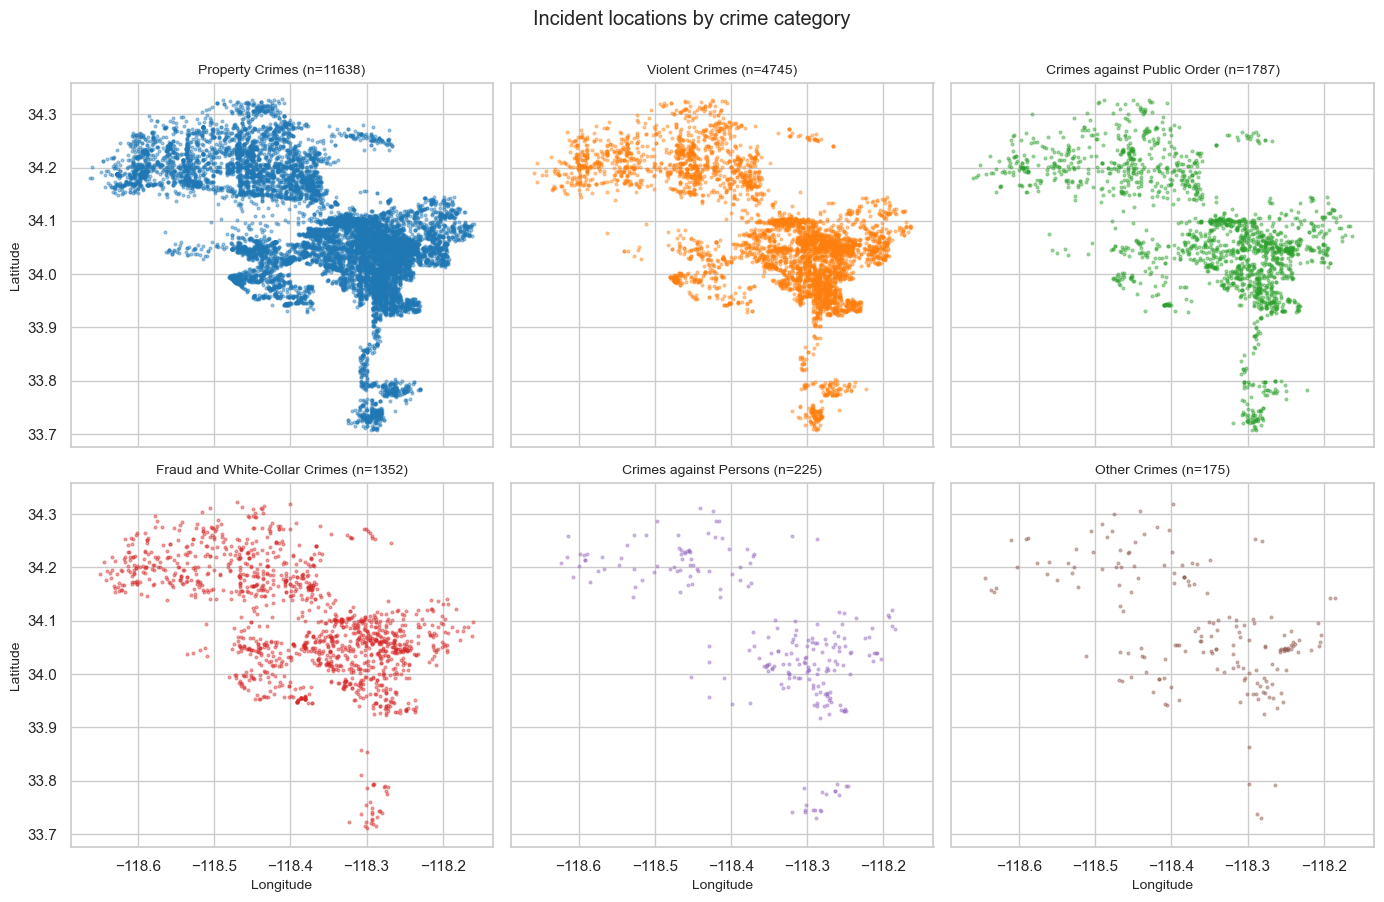

In [48]:
# figure 32: location by crime category, one panel each
fig, axes = plt.subplots(2, 3, figsize=(14, 9), sharex=True, sharey=True)
for ax, cat in zip(axes.ravel(), cat_order):
    d = eda[(eda.Crime_Category == cat) & eda.valid_geo]
    ax.scatter(d.Longitude, d.Latitude, s=4, alpha=0.4, color=palette[cat])
    ax.set_title(f'{cat} (n={len(d)})', fontsize=10)
for ax in axes[1]:
    ax.set_xlabel('Longitude')
for ax in axes[:, 0]:
    ax.set_ylabel('Latitude')
fig.suptitle('Incident locations by crime category', y=1.0)
show('fig32_location_by_category')

distinct MO codes: 481


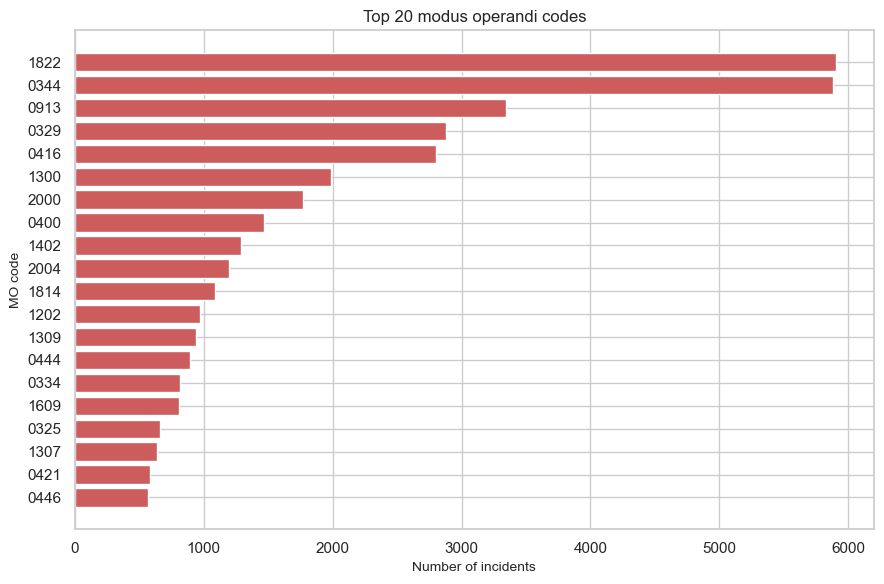

In [49]:
# figure 33: most frequent modus operandi codes
codes = eda.Modus_Operandi.dropna().str.split().explode()
mo_top = codes.value_counts().head(20)
print('distinct MO codes:', codes.nunique())
plt.figure(figsize=(9, 6))
plt.barh(mo_top.index[::-1], mo_top.values[::-1], color='indianred')
plt.title('Top 20 modus operandi codes')
plt.xlabel('Number of incidents')
plt.ylabel('MO code')
show('fig33_top_mo_codes')

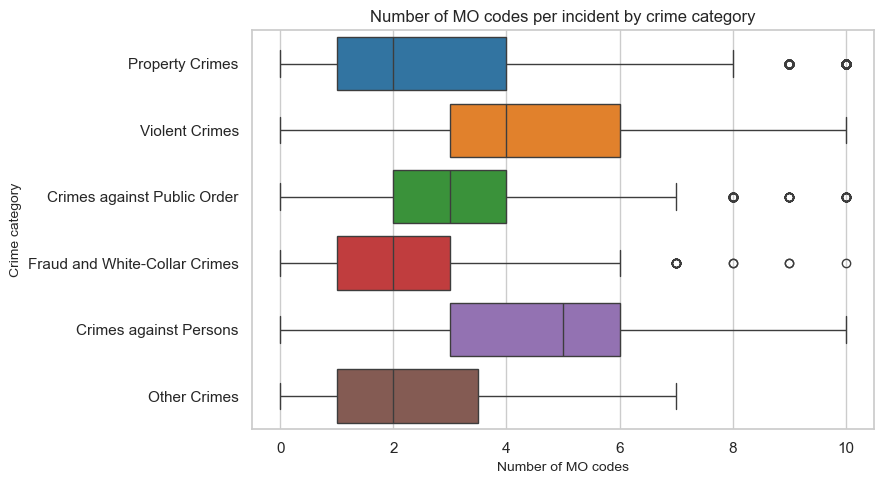

In [50]:
# figure 34: number of MO codes per incident by category
eda['n_mo'] = eda.Modus_Operandi.fillna('').str.split().str.len()
plt.figure(figsize=(9, 5))
sns.boxplot(data=eda, x='n_mo', y='Crime_Category', order=cat_order,
            hue='Crime_Category', palette=palette, legend=False)
plt.title('Number of MO codes per incident by crime category')
plt.xlabel('Number of MO codes')
plt.ylabel('Crime category')
show('fig34_mo_count_by_category')

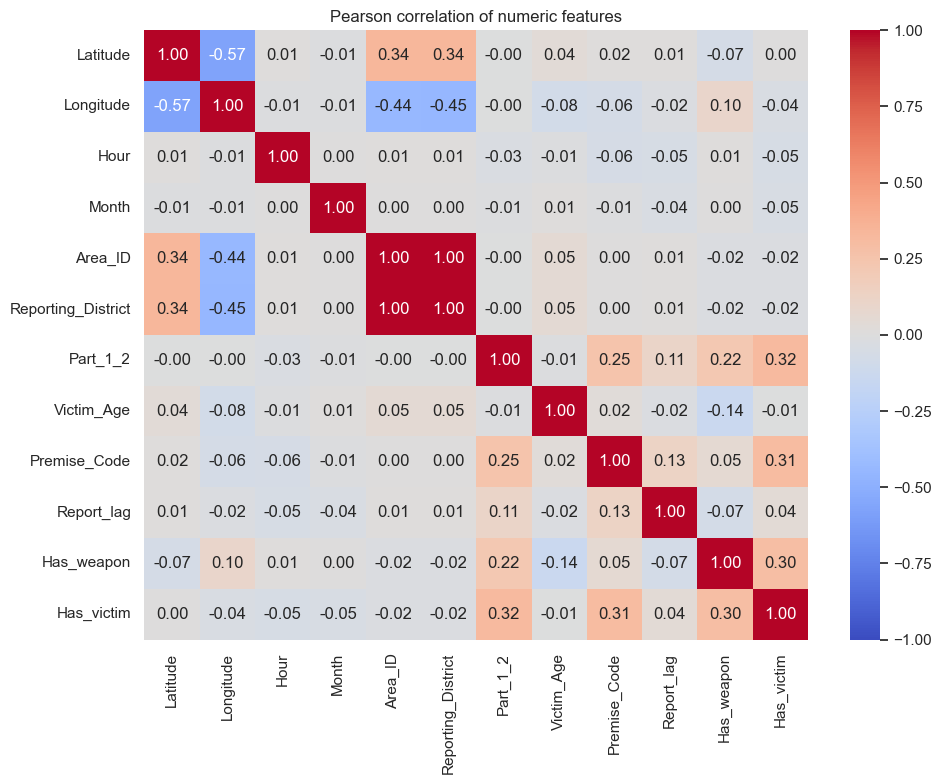

In [51]:
# figure 35: correlation of numeric features
num = pd.DataFrame({
    'Latitude': eda.Latitude.where(eda.valid_geo),
    'Longitude': eda.Longitude.where(eda.valid_geo),
    'Hour': eda.hour,
    'Month': eda.month,
    'Area_ID': eda.Area_ID,
    'Reporting_District': eda.Reporting_District_no,
    'Part_1_2': eda['Part 1-2'],
    'Victim_Age': eda.age_clean,
    'Premise_Code': eda.Premise_Code,
    'Report_lag': eda.report_lag,
    'Has_weapon': eda.has_weapon.astype(int),
    'Has_victim': eda.has_victim.astype(int),
})
plt.figure(figsize=(10, 8))
sns.heatmap(num.corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1)
plt.title('Pearson correlation of numeric features')
show('fig35_correlation')

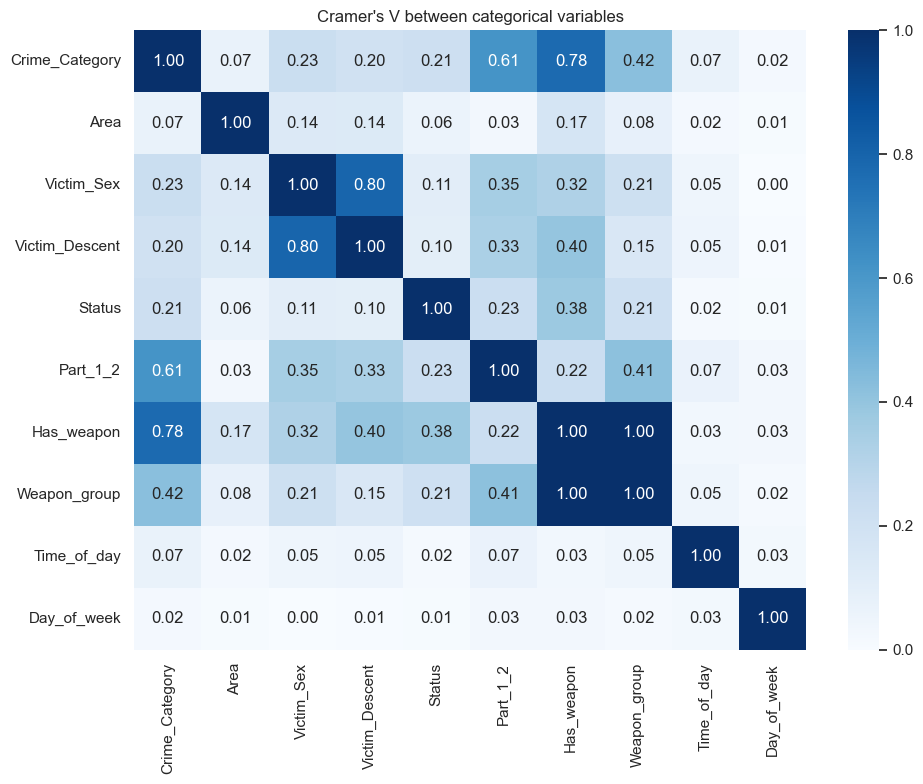

In [52]:
# figure 36: Cramer's V between categorical variables
def cramers_v(a, b):
    ct = pd.crosstab(a, b)
    chi2 = stats.chi2_contingency(ct)[0]
    n = ct.values.sum()
    phi2 = chi2 / n
    r, k = ct.shape
    phi2c = max(0, phi2 - (k - 1) * (r - 1) / (n - 1))
    rc = r - (r - 1) ** 2 / (n - 1)
    kc = k - (k - 1) ** 2 / (n - 1)
    return np.sqrt(phi2c / min(kc - 1, rc - 1))

cat_df = pd.DataFrame({
    'Crime_Category': eda.Crime_Category,
    'Area': eda.Area_Name,
    'Victim_Sex': eda.sex,
    'Victim_Descent': eda.descent,
    'Status': eda.Status_Description,
    'Part_1_2': eda['Part 1-2'],
    'Has_weapon': eda.has_weapon,
    'Weapon_group': eda.weapon_group,
    'Time_of_day': eda.time_of_day.astype(str),
    'Day_of_week': eda.dow,
})
names = cat_df.columns
cv = pd.DataFrame(np.eye(len(names)), index=names, columns=names)
for i, a in enumerate(names):
    for b in names[i + 1:]:
        cv.loc[a, b] = cv.loc[b, a] = cramers_v(cat_df[a], cat_df[b])
plt.figure(figsize=(10, 8))
sns.heatmap(cv, annot=True, fmt='.2f', cmap='Blues', vmin=0, vmax=1)
plt.title("Cramer's V between categorical variables")
show('fig36_cramers_v')

In [53]:
# association of each feature with the target
rows = []
for col in ['Area', 'Victim_Sex', 'Victim_Descent', 'Status', 'Part_1_2', 'Has_weapon',
            'Weapon_group', 'Time_of_day', 'Day_of_week']:
    ct = pd.crosstab(cat_df[col], cat_df.Crime_Category)
    chi2, p, dof, _ = stats.chi2_contingency(ct)
    rows.append([col, 'chi-square', round(chi2, 1), p, round(cv.loc[col, 'Crime_Category'], 3)])
for col, series in [('Victim_Age', eda.age_clean), ('Hour', eda.hour), ('Report_lag', eda.report_lag)]:
    groups = [series[eda.Crime_Category == k].dropna() for k in cat_order]
    h, p = stats.kruskal(*groups)
    rows.append([col, 'kruskal-wallis', round(h, 1), p, np.nan])
assoc = pd.DataFrame(rows, columns=['feature', 'test', 'statistic', 'p_value', 'cramers_v'])
assoc['p_value'] = assoc.p_value.map(lambda x: f'{x:.2e}')
assoc

,feature,test,statistic,p_value,cramers_v
0,Area,chi-square,615.2,4.12e-75,0.072
1,Victim_Sex,chi-square,3164.3,0.00e+00,0.229
2,Victim_Descent,chi-square,4059.2,0.00e+00,0.199
3,Status,chi-square,3715.6,0.00e+00,0.215
4,Part_1_2,chi-square,7551.2,0.00e+00,0.614
5,Has_weapon,chi-square,12085.4,0.00e+00,0.777
6,Weapon_group,chi-square,17976.9,0.00e+00,0.424
7,Time_of_day,chi-square,338.5,5.45e-63,0.073
8,Day_of_week,chi-square,83.7,5.71e-07,0.023
9,Victim_Age,kruskal-wallis,692.2,2.42e-147,NaN


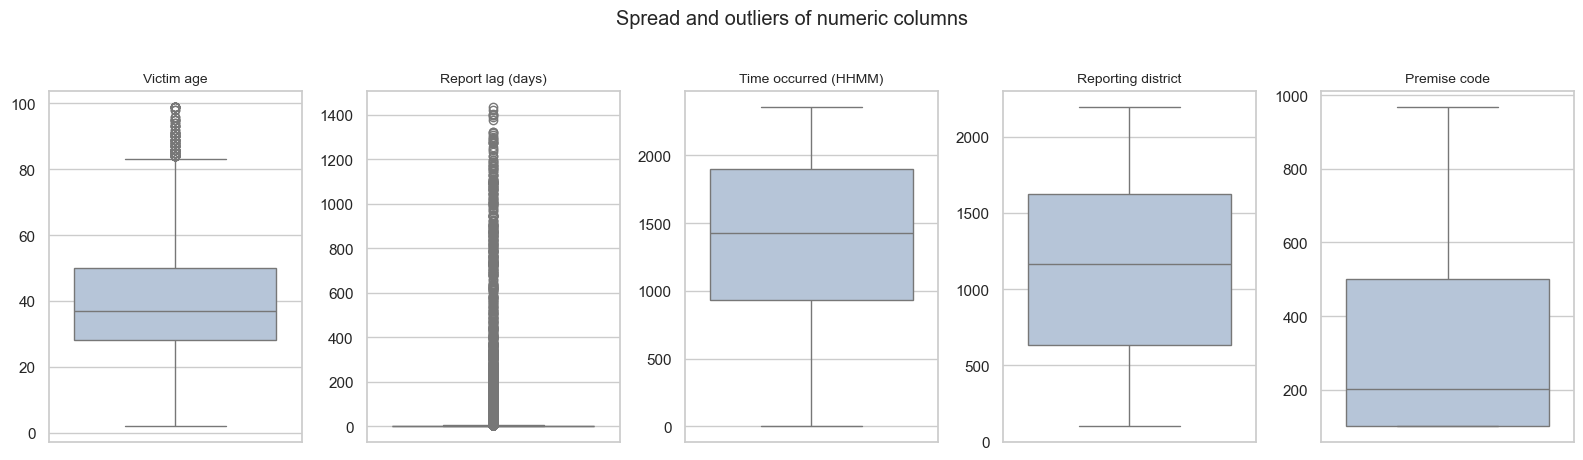

In [54]:
# figure 37: spread and outliers in numeric columns
fig, axes = plt.subplots(1, 5, figsize=(16, 4.5))
for ax, (col, series) in zip(axes, [('Victim age', eda.age_clean), ('Report lag (days)', eda.report_lag),
                                    ('Time occurred (HHMM)', eda.Time_Occurred),
                                    ('Reporting district', eda.Reporting_District_no),
                                    ('Premise code', eda.Premise_Code)]):
    sns.boxplot(y=series.dropna(), ax=ax, color='lightsteelblue')
    ax.set_title(col, fontsize=10)
    ax.set_ylabel('')
fig.suptitle('Spread and outliers of numeric columns', y=1.02)
show('fig37_numeric_boxplots')

In [55]:
# step 1: remove duplicates and fix invalid values (row level, no statistics learned)
base = df.drop_duplicates().reset_index(drop=True).copy()
print('rows after removing duplicates:', len(base), 'removed:', len(df) - len(base))

base['has_weapon'] = base.Weapon_Description.notna().astype(int)
base['has_victim'] = base.Victim_Sex.notna().astype(int)
base['has_MO'] = base.Modus_Operandi.notna().astype(int)
base['has_cross_street'] = base.Cross_Street.notna().astype(int)
base['age_missing'] = (base.Victim_Age <= 0).astype(int)
base['geo_missing'] = ((base.Latitude == 0) | (base.Longitude == 0)).astype(int)

base['Victim_Sex'] = base.Victim_Sex.replace({'H': 'Unknown'}).fillna('Unknown')
base['Victim_Descent'] = base.Victim_Descent.fillna('Unknown')
base['Premise_Description'] = base.Premise_Description.fillna('UNKNOWN')
base['Modus_Operandi'] = base.Modus_Operandi.fillna('')
base.loc[base.Victim_Age <= 0, 'Victim_Age'] = np.nan
base.loc[base.geo_missing == 1, ['Latitude', 'Longitude']] = np.nan

base.isna().sum()[lambda s: s > 0]

rows after removing duplicates: 19987 removed: 13


Cross_Street          16540
Latitude                 78
Longitude                78
Victim_Age             4825
Weapon_Used_Code      12657
Weapon_Description    12657
dtype: int64

In [56]:
# step 2: feature engineering (row level)
base['date_occ'] = pd.to_datetime(base.Date_Occurred, format=fmt)
base['date_rep'] = pd.to_datetime(base.Date_Reported, format=fmt)

feat = pd.DataFrame(index=base.index)
feat['Latitude'] = base.Latitude
feat['Longitude'] = base.Longitude
feat['Victim_Age'] = base.Victim_Age
feat['hour'] = (base.Time_Occurred // 100).astype(int)
feat['month'] = base.date_occ.dt.month
feat['day_of_year'] = base.date_occ.dt.dayofyear
feat['dow_num'] = base.date_occ.dt.dayofweek
feat['is_weekend'] = (feat.dow_num >= 5).astype(int)
feat['hour_sin'] = np.sin(2 * np.pi * feat.hour / 24)
feat['hour_cos'] = np.cos(2 * np.pi * feat.hour / 24)
feat['report_lag_log'] = np.log1p((base.date_rep - base.date_occ).dt.days.clip(0, 365))
feat['n_mo_codes'] = base.Modus_Operandi.str.split().str.len()
feat['part2'] = (base['Part 1-2'] == 2).astype(int)
for col in ['has_weapon', 'has_victim', 'has_MO', 'has_cross_street', 'age_missing', 'geo_missing']:
    feat[col] = base[col]

feat['Area_Name'] = base.Area_Name
feat['Victim_Sex'] = base.Victim_Sex
feat['Victim_Descent'] = base.Victim_Descent
feat['Status_Description'] = base.Status_Description
feat['weapon_group'] = base.Weapon_Description.apply(weapon_group)
feat['time_of_day'] = pd.cut(feat.hour, [-1, 5, 11, 17, 23],
                             labels=['late_night', 'morning', 'afternoon', 'evening']).astype(str)
feat['premise_range'] = (base.Premise_Code // 100).astype(int).astype(str)
feat['Premise_Description'] = base.Premise_Description
feat['Reporting_District_no'] = base.Reporting_District_no
feat['MO'] = base.Modus_Operandi

target_names = sorted(base.Crime_Category.unique())
le = LabelEncoder().fit(target_names)
y_all = pd.Series(le.transform(base.Crime_Category), index=base.index, name='Crime_Category')
print('classes:', {str(k): i for i, k in enumerate(le.classes_)})
feat.head()

classes: {'Crimes against Persons': 0, 'Crimes against Public Order': 1, 'Fraud and White-Collar Crimes': 2, 'Other Crimes': 3, 'Property Crimes': 4, 'Violent Crimes': 5}


,Latitude,Longitude,Victim_Age,hour,month,day_of_year,dow_num,is_weekend,hour_sin,hour_cos,report_lag_log,n_mo_codes,part2,has_weapon,has_victim,has_MO,has_cross_street,age_missing,geo_missing,Area_Name,Victim_Sex,Victim_Descent,Status_Description,weapon_group,time_of_day,premise_range,Premise_Description,Reporting_District_no,MO
0,34.1522,-118.3910,75.0,18,3,66,4,0,-1.000000,-1.836970e-16,1.386294,1,0,0,1,1,0,0,0,N Hollywood,M,W,Invest Cont,None recorded,evening,1,STREET,1563.0,0385
1,34.0028,-118.2391,41.0,13,2,58,3,0,-0.258819,-9.659258e-01,0.000000,8,0,1,1,1,1,0,0,Newton,M,H,Invest Cont,Bodily force,afternoon,2,SWAP MEET,1367.0,0906 0352 0371 0446 1822 0344 0416 0417
2,34.0111,-118.2653,67.0,6,8,234,4,0,1.000000,6.123234e-17,0.000000,2,1,0,1,1,0,0,0,Newton,M,B,Invest Cont,None recorded,morning,5,SINGLE FAMILY DWELLING,1343.0,0329 1202
3,34.2953,-118.4590,61.0,18,11,311,4,0,-1.000000,-1.836970e-16,1.098612,2,0,0,1,1,0,0,0,Mission,M,H,Invest Cont,None recorded,evening,1,STREET,1924.0,0329 1300
4,33.9787,-118.2918,NaN,11,2,56,1,0,0.258819,-9.659258e-01,0.000000,6,0,1,1,1,0,1,0,77th Street,X,X,Invest Cont,Bodily force,morning,4,MINI-MART,1245.0,0416 0945 1822 0400 0417 0344


In [57]:
# step 3: stratified train / test split (before any fitted preprocessing)
X_tr_raw, X_te_raw, y_tr, y_te = train_test_split(
    feat, y_all, test_size=0.20, stratify=y_all, random_state=SEED)
print('train:', X_tr_raw.shape, 'test:', X_te_raw.shape)
split_table = pd.DataFrame({
    'train_n': y_tr.map(dict(enumerate(le.classes_))).value_counts(),
    'test_n': y_te.map(dict(enumerate(le.classes_))).value_counts(),
})
split_table['train_pct'] = (split_table.train_n / len(y_tr) * 100).round(2)
split_table['test_pct'] = (split_table.test_n / len(y_te) * 100).round(2)
split_table

train: (15989, 29) test: (3998, 29)


,train_n,test_n,train_pct,test_pct
Crime_Category,,,,
Property Crimes,9327,2332,58.33,58.33
Violent Crimes,3810,952,23.83,23.81
Crimes against Public Order,1446,362,9.04,9.05
Fraud and White-Collar Crimes,1083,271,6.77,6.78
Crimes against Persons,180,45,1.13,1.13
Other Crimes,143,36,0.89,0.90


In [58]:
# step 4: statistics learned from the training split only
cat_cols = ['Area_Name', 'Victim_Sex', 'Victim_Descent', 'Status_Description',
            'weapon_group', 'time_of_day', 'premise_range']
age_median = X_tr_raw.Victim_Age.median()
geo_med = X_tr_raw.groupby('Area_Name')[['Latitude', 'Longitude']].median()
geo_global = X_tr_raw[['Latitude', 'Longitude']].median()
prem_freq = X_tr_raw.Premise_Description.value_counts(normalize=True)
dist_freq = X_tr_raw.Reporting_District_no.value_counts(normalize=True)
mo_counts = Counter(code for s in X_tr_raw.MO for code in s.split())
top_mo = [code for code, _ in mo_counts.most_common(30)]
ohe = OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=30, sparse_output=False)
ohe.fit(X_tr_raw[cat_cols])

print('age median:', age_median)
print('top MO codes:', top_mo[:10], '...')
print('one-hot columns:', len(ohe.get_feature_names_out(cat_cols)))

age median: 37.0
top MO codes: ['1822', '0344', '0913', '0329', '0416', '1300', '2000', '0400', '1402', '2004'] ...
one-hot columns: 62


In [59]:
# step 5: apply imputation and encoding
base_cols = ['Latitude', 'Longitude', 'Victim_Age', 'hour', 'month', 'day_of_year', 'dow_num', 'is_weekend',
             'hour_sin', 'hour_cos', 'report_lag_log', 'n_mo_codes', 'part2', 'has_weapon', 'has_victim',
             'has_MO', 'has_cross_street', 'age_missing', 'geo_missing']

def transform(X):
    X = X.copy()
    for col in ['Latitude', 'Longitude']:
        X[col] = X[col].fillna(X.Area_Name.map(geo_med[col])).fillna(geo_global[col])
    X['Victim_Age'] = X.Victim_Age.fillna(age_median)
    X['premise_freq'] = X.Premise_Description.map(prem_freq).fillna(0)
    X['district_freq'] = X.Reporting_District_no.map(dist_freq).fillna(0)
    code_sets = X.MO.str.split().apply(set)
    mo_df = pd.DataFrame({f'mo_{code}': code_sets.apply(lambda s, code=code: int(code in s)) for code in top_mo},
                         index=X.index)
    oh = pd.DataFrame(ohe.transform(X[cat_cols]), columns=ohe.get_feature_names_out(cat_cols), index=X.index)
    return pd.concat([X[base_cols + ['premise_freq', 'district_freq']], mo_df, oh], axis=1)

X_tr = transform(X_tr_raw)
X_te = transform(X_te_raw)
print('feature matrix:', X_tr.shape, X_te.shape)
print('missing values left:', int(X_tr.isna().sum().sum()), int(X_te.isna().sum().sum()))
X_tr.head()

feature matrix: (15989, 113) (3998, 113)
missing values left: 0 0


,Latitude,Longitude,Victim_Age,hour,month,day_of_year,dow_num,is_weekend,hour_sin,hour_cos,report_lag_log,n_mo_codes,part2,has_weapon,has_victim,has_MO,has_cross_street,age_missing,geo_missing,premise_freq,district_freq,mo_1822,mo_0344,mo_0913,mo_0329,mo_0416,mo_1300,mo_2000,mo_0400,mo_1402,mo_2004,mo_1814,mo_1202,mo_1309,mo_0444,mo_0334,mo_1609,mo_0325,mo_1307,mo_0421,mo_0446,mo_0342,mo_1501,mo_1606,mo_1813,mo_1218,mo_0432,mo_0448,mo_0429,mo_0906,mo_1607,Area_Name_77th Street,Area_Name_Central,Area_Name_Devonshire,Area_Name_Foothill,Area_Name_Harbor,Area_Name_Hollenbeck,Area_Name_Hollywood,Area_Name_Mission,Area_Name_N Hollywood,Area_Name_Newton,Area_Name_Northeast,Area_Name_Olympic,Area_Name_Pacific,Area_Name_Rampart,Area_Name_Southeast,Area_Name_Southwest,Area_Name_Topanga,Area_Name_Van Nuys,Area_Name_West LA,Area_Name_West Valley,Area_Name_Wilshire,Victim_Sex_F,Victim_Sex_M,Victim_Sex_Unknown,Victim_Sex_X,Victim_Descent_A,Victim_Descent_B,Victim_Descent_C,Victim_Descent_F,Victim_Descent_H,Victim_Descent_K,Victim_Descent_O,Victim_Descent_Unknown,Victim_Descent_W,Victim_Descent_X,Victim_Descent_infrequent_sklearn,Status_Description_Adult Arrest,Status_Description_Adult Other,Status_Description_Invest Cont,Status_Description_Juv Arrest,Status_Description_Juv Other,weapon_group_Blade or sharp object,weapon_group_Blunt or thrown object,weapon_group_Bodily force,weapon_group_Firearm,weapon_group_Imitation or non-lethal,weapon_group_None recorded,weapon_group_Other,weapon_group_Verbal threat,time_of_day_afternoon,time_of_day_evening,time_of_day_late_night,time_of_day_morning,premise_range_1,premise_range_2,premise_range_3,premise_range_4,premise_range_5,premise_range_6,premise_range_7,premise_range_8,premise_range_9
3598,33.9882,-118.4699,51.0,3,11,309,2,0,7.071068e-01,0.707107,1.098612,2,0,0,1,1,0,0,0,0.251923,0.003377,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
19085,33.7958,-118.2937,45.0,12,6,157,4,0,1.224647e-16,-1.000000,2.197225,4,1,1,1,1,0,0,0,0.126712,0.000938,0,0,1,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
8245,34.1985,-118.4749,37.0,20,4,103,6,1,-8.660254e-01,0.500000,0.000000,6,1,1,1,1,0,1,0,0.251923,0.000938,1,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4735,34.0707,-118.2143,34.0,10,11,334,6,1,5.000000e-01,-0.866025,0.000000,6,0,1,1,1,0,0,0,0.167490,0.001126,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
16535,34.2537,-118.5886,39.0,20,2,60,5,1,-8.660254e-01,0.500000,0.000000,5,1,1,1,1,0,0,0,0.126712,0.000688,0,0,1,0,0,0,1,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0


In [60]:
# step 6: scaling (fit on train, apply to test)
cont_cols = ['Latitude', 'Longitude', 'Victim_Age', 'hour', 'month', 'day_of_year', 'dow_num',
             'report_lag_log', 'n_mo_codes', 'premise_freq', 'district_freq']
scaler = StandardScaler().fit(X_tr[cont_cols])
X_tr_s = X_tr.copy()
X_te_s = X_te.copy()
X_tr_s[cont_cols] = scaler.transform(X_tr[cont_cols])
X_te_s[cont_cols] = scaler.transform(X_te[cont_cols])
pd.DataFrame({'train_mean': X_tr_s[cont_cols].mean().round(3), 'train_std': X_tr_s[cont_cols].std().round(3),
              'test_mean': X_te_s[cont_cols].mean().round(3), 'test_std': X_te_s[cont_cols].std().round(3)})

,train_mean,train_std,test_mean,test_std
Latitude,0.0,1.0,-0.001,1.018
Longitude,0.0,1.0,-0.007,1.002
Victim_Age,0.0,1.0,0.012,0.999
hour,-0.0,1.0,0.008,0.987
month,0.0,1.0,0.011,1.005
day_of_year,0.0,1.0,0.009,1.004
dow_num,0.0,1.0,0.012,0.987
report_lag_log,0.0,1.0,0.016,1.035
n_mo_codes,0.0,1.0,-0.002,0.991
premise_freq,0.0,1.0,-0.008,1.004


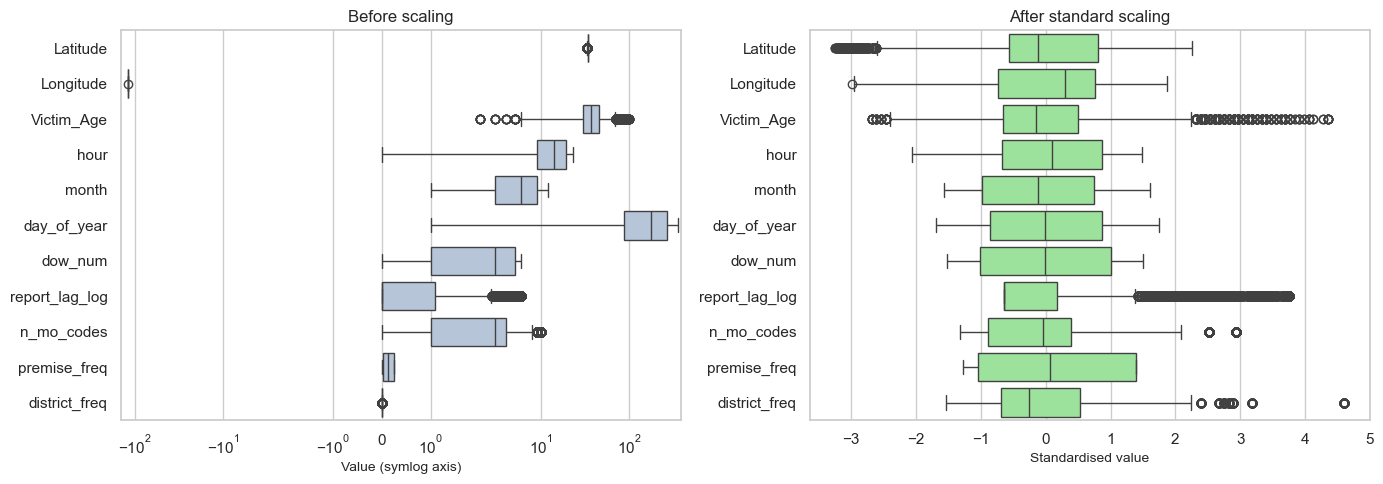

In [61]:
# figure 38: effect of scaling on continuous features
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=X_tr[cont_cols], orient='h', ax=axes[0], color='lightsteelblue')
axes[0].set_title('Before scaling')
axes[0].set_xscale('symlog')
axes[0].set_xlabel('Value (symlog axis)')
sns.boxplot(data=X_tr_s[cont_cols], orient='h', ax=axes[1], color='lightgreen')
axes[1].set_title('After standard scaling')
axes[1].set_xlabel('Standardised value')
show('fig38_scaling_effect')

In [62]:
# step 7a: remove constant and near constant features
freq_min = 0.005
keep = []
dropped_low = []
for col in X_tr.columns:
    if X_tr[col].nunique() <= 1:
        dropped_low.append(col)
    elif set(X_tr[col].unique()) <= {0, 1} and (X_tr[col].mean() < freq_min or X_tr[col].mean() > 1 - freq_min):
        dropped_low.append(col)
    else:
        keep.append(col)
print('dropped (near constant):', dropped_low)
print('remaining:', len(keep))

dropped (near constant): ['geo_missing', 'Victim_Descent_C', 'Victim_Descent_F', 'Victim_Descent_K', 'Victim_Descent_infrequent_sklearn', 'Status_Description_Juv Arrest', 'Status_Description_Juv Other', 'weapon_group_Imitation or non-lethal', 'premise_range_6', 'premise_range_8', 'premise_range_9']
remaining: 102


In [63]:
# step 7b: remove one of each highly correlated pair
corr = X_tr_s[keep].corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
dropped_corr = [col for col in upper.columns if (upper[col] > 0.90).any()]
keep2 = [col for col in keep if col not in dropped_corr]
print('dropped (correlation > 0.90):', dropped_corr)
print('remaining:', len(keep2))

dropped (correlation > 0.90): ['day_of_year', 'has_MO', 'Victim_Sex_Unknown', 'Victim_Descent_Unknown', 'Victim_Descent_X', 'weapon_group_None recorded']
remaining: 96


In [64]:
# step 7c: mutual information and random forest importance on the training split
discrete_mask = np.array([X_tr[col].nunique() <= 2 for col in keep2])
mi = mutual_info_classif(X_tr[keep2], y_tr, discrete_features=discrete_mask, random_state=SEED)
mi = pd.Series(mi, index=keep2).sort_values(ascending=False)

rf_sel = RandomForestClassifier(n_estimators=200, min_samples_leaf=2, class_weight='balanced_subsample',
                                n_jobs=-1, random_state=SEED).fit(X_tr[keep2], y_tr)
rf_imp = pd.Series(rf_sel.feature_importances_, index=keep2).sort_values(ascending=False)

rank_table = pd.DataFrame({
    'mutual_info': mi,
    'rf_importance': rf_imp,
})
rank_table['mi_rank'] = rank_table.mutual_info.rank(ascending=False)
rank_table['rf_rank'] = rank_table.rf_importance.rank(ascending=False)
rank_table['mean_rank'] = rank_table[['mi_rank', 'rf_rank']].mean(axis=1)
rank_table = rank_table.sort_values('mean_rank')
rank_table.head(25).round(4)

,mutual_info,rf_importance,mi_rank,rf_rank,mean_rank
has_weapon,0.3527,0.0653,1.0,3.0,2.0
part2,0.2120,0.0769,3.0,2.0,2.5
weapon_group_Bodily force,0.2163,0.0459,2.0,5.0,3.5
mo_0344,0.1618,0.0368,4.0,6.0,5.0
Victim_Age,0.1092,0.1090,10.0,1.0,5.5
report_lag_log,0.1178,0.0578,9.0,4.0,6.5
n_mo_codes,0.1286,0.0282,7.0,7.0,7.0
premise_freq,0.1376,0.0250,6.0,10.0,8.0
mo_0416,0.1504,0.0235,5.0,12.0,8.5
Status_Description_Invest Cont,0.0838,0.0184,12.0,16.0,14.0


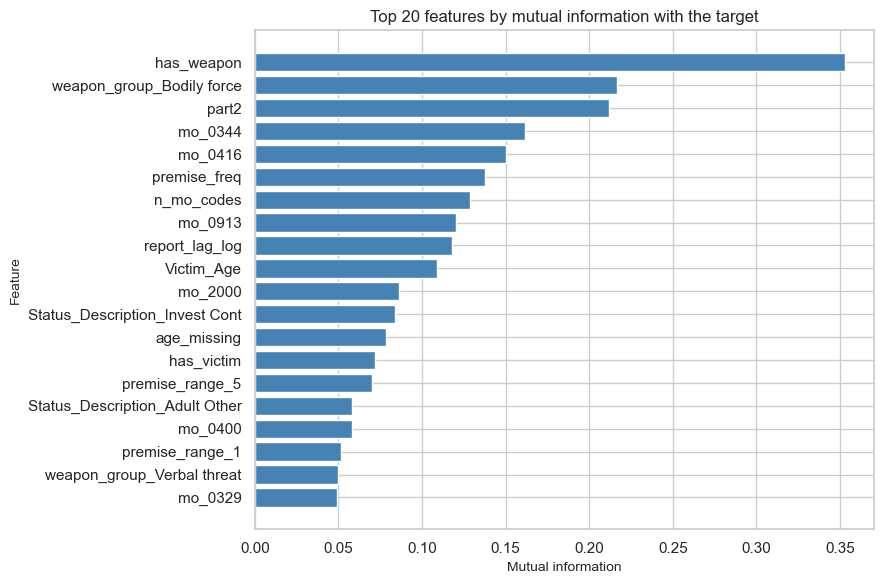

In [65]:
# figure 39: mutual information, top 20
plt.figure(figsize=(9, 6))
t = mi.head(20)
plt.barh(t.index[::-1], t.values[::-1], color='steelblue')
plt.title('Top 20 features by mutual information with the target')
plt.xlabel('Mutual information')
plt.ylabel('Feature')
show('fig39_mutual_information')

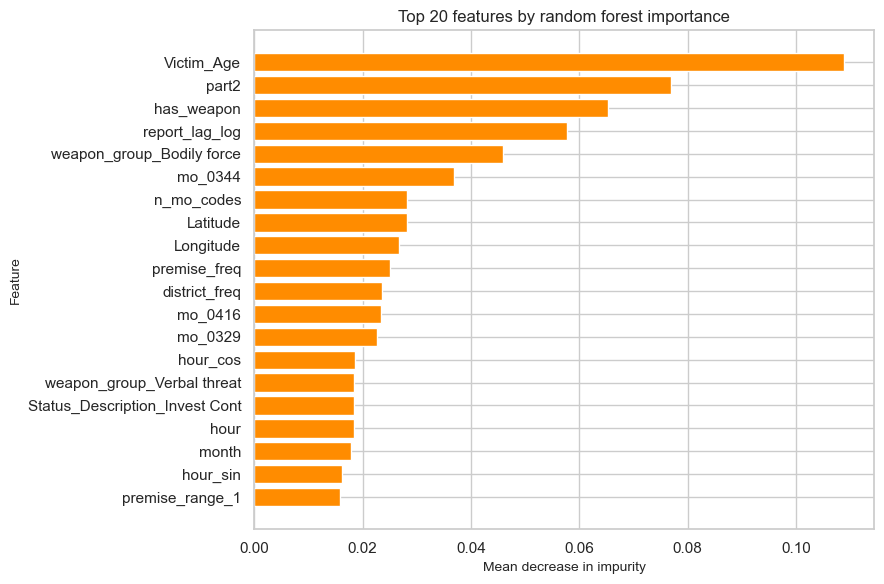

In [66]:
# figure 40: random forest importance, top 20
plt.figure(figsize=(9, 6))
t = rf_imp.head(20)
plt.barh(t.index[::-1], t.values[::-1], color='darkorange')
plt.title('Top 20 features by random forest importance')
plt.xlabel('Mean decrease in impurity')
plt.ylabel('Feature')
show('fig40_rf_importance')

In [67]:
# step 7d: choose the number of features with 3-fold cross validation on the training split
ordered = rank_table.index.tolist()
ks = [10, 20, 30, 40, 60, len(ordered)]
skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
cv_scores = []
for k in ks:
    rf_k = RandomForestClassifier(n_estimators=100, class_weight='balanced_subsample', min_samples_leaf=2,
                                  n_jobs=-1, random_state=SEED)
    s = cross_val_score(rf_k, X_tr[ordered[:k]], y_tr, cv=skf, scoring='f1_macro').mean()
    cv_scores.append(s)
    print(k, round(s, 4))

10 0.6655
20 0.7476
30 0.7528
40 0.7569
60 0.7388
96 0.7423


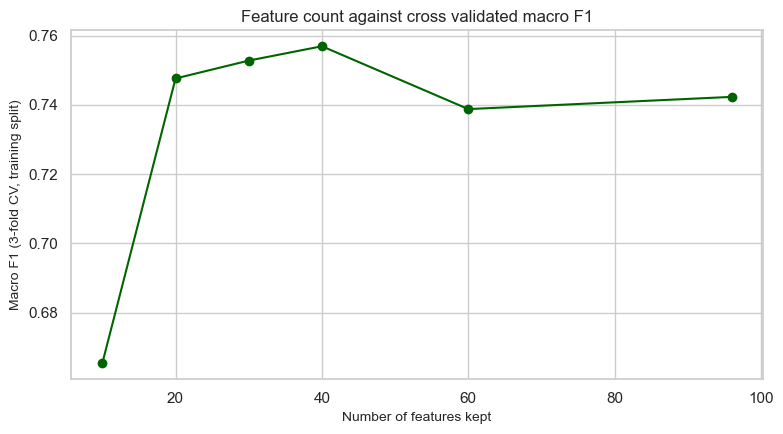

In [68]:
# figure 41: cross validated macro F1 against number of features
plt.figure(figsize=(8, 4.5))
plt.plot(ks, cv_scores, marker='o', color='darkgreen')
plt.xlabel('Number of features kept')
plt.ylabel('Macro F1 (3-fold CV, training split)')
plt.title('Feature count against cross validated macro F1')
show('fig41_feature_count_cv')

In [69]:
# final feature set: smallest k within 0.005 of the best score
best = max(cv_scores)
k_final = min(k for k, s in zip(ks, cv_scores) if s >= best - 0.005)
selected = ordered[:k_final]
print('best macro F1:', round(best, 4))
print('features kept:', k_final)
print(selected)

best macro F1: 0.7569
features kept: 30
['has_weapon', 'part2', 'weapon_group_Bodily force', 'mo_0344', 'Victim_Age', 'report_lag_log', 'n_mo_codes', 'premise_freq', 'mo_0416', 'Status_Description_Invest Cont', 'mo_0913', 'mo_0329', 'weapon_group_Verbal threat', 'Longitude', 'premise_range_5', 'mo_2000', 'premise_range_1', 'age_missing', 'has_victim', 'hour', 'hour_cos', 'Latitude', 'Status_Description_Adult Other', 'mo_0421', 'mo_1501', 'Victim_Descent_H', 'Victim_Sex_F', 'mo_1814', 'mo_0400', 'mo_0334']


In [70]:
# class weights and final matrices
classes = np.unique(y_tr)
cw = compute_class_weight('balanced', classes=classes, y=y_tr)
class_weights = {str(le.classes_[i]): round(float(w), 3) for i, w in zip(classes, cw)}
print(class_weights)

Xtr_final = X_tr[selected]
Xte_final = X_te[selected]
Xtr_final_s = X_tr_s[selected]
Xte_final_s = X_te_s[selected]
print(Xtr_final.shape, Xte_final.shape)

{'Crimes against Persons': 14.805, 'Crimes against Public Order': 1.843, 'Fraud and White-Collar Crimes': 2.461, 'Other Crimes': 18.635, 'Property Crimes': 0.286, 'Violent Crimes': 0.699}
(15989, 30) (3998, 30)


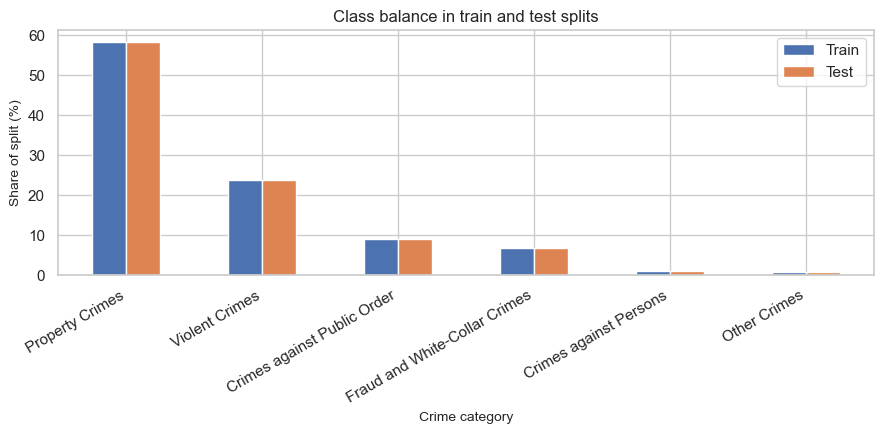

In [71]:
# figure 42: class balance in the train and test splits
cmp = pd.DataFrame({
    'Train': y_tr.map(dict(enumerate(le.classes_))).value_counts(normalize=True) * 100,
    'Test': y_te.map(dict(enumerate(le.classes_))).value_counts(normalize=True) * 100,
}).loc[cat_order]
cmp.plot(kind='bar', figsize=(9, 4.5), color=['#4c72b0', '#dd8452'])
plt.title('Class balance in train and test splits')
plt.xlabel('Crime category')
plt.ylabel('Share of split (%)')
plt.xticks(rotation=30, ha='right')
show('fig42_split_balance')

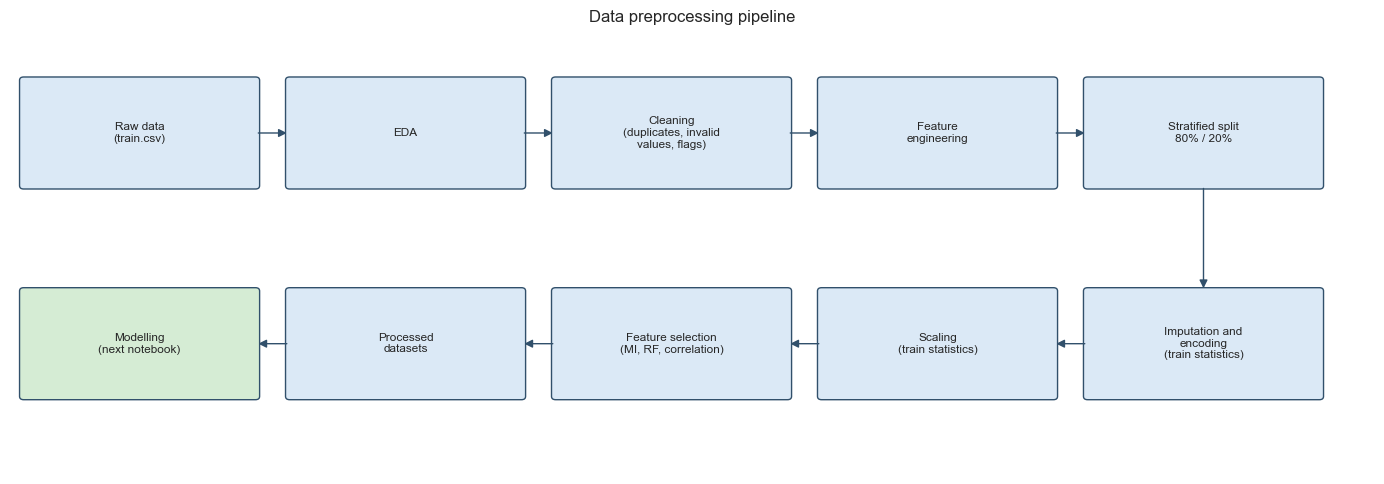

In [72]:
# figure 43: preprocessing pipeline
steps = ['Raw data\n(train.csv)', 'EDA', 'Cleaning\n(duplicates, invalid\nvalues, flags)',
         'Feature\nengineering', 'Stratified split\n80% / 20%',
         'Imputation and\nencoding\n(train statistics)', 'Scaling\n(train statistics)',
         'Feature selection\n(MI, RF, correlation)', 'Processed\ndatasets', 'Modelling\n(next notebook)']
fig, ax = plt.subplots(figsize=(14, 5))
ax.set_xlim(0, 10); ax.set_ylim(0, 4); ax.axis('off')
pos = [(0.1 + i * 1.95, 2.6) for i in range(5)] + [(0.1 + (4 - i) * 1.95, 0.7) for i in range(5)]
w, h = 1.7, 0.95
for i, ((x, y), s) in enumerate(zip(pos, steps)):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle='round,pad=0.03', fc='#dbe9f6' if i < 9 else '#d5ecd4', ec='#31506b'))
    ax.text(x + w / 2, y + h / 2, s, ha='center', va='center', fontsize=8.5)
for i in range(len(pos) - 1):
    (x1, y1), (x2, y2) = pos[i], pos[i + 1]
    if i == 4:
        ax.add_patch(FancyArrowPatch((x1 + w / 2, y1), (x2 + w / 2, y2 + h), arrowstyle='-|>', mutation_scale=12, color='#31506b'))
    elif i < 4:
        ax.add_patch(FancyArrowPatch((x1 + w, y1 + h / 2), (x2, y2 + h / 2), arrowstyle='-|>', mutation_scale=12, color='#31506b'))
    else:
        ax.add_patch(FancyArrowPatch((x1, y1 + h / 2), (x2 + w, y2 + h / 2), arrowstyle='-|>', mutation_scale=12, color='#31506b'))
ax.set_title('Data preprocessing pipeline')
show('fig43_pipeline')

In [73]:
# save processed data and fitted objects
ytr_s = pd.Series(y_tr.values, name='Crime_Category')
yte_s = pd.Series(y_te.values, name='Crime_Category')
Xtr_final.reset_index(drop=True).to_csv('processed/X_train.csv', index=False)
Xte_final.reset_index(drop=True).to_csv('processed/X_test.csv', index=False)
Xtr_final_s.reset_index(drop=True).to_csv('processed/X_train_scaled.csv', index=False)
Xte_final_s.reset_index(drop=True).to_csv('processed/X_test_scaled.csv', index=False)
ytr_s.to_csv('processed/y_train.csv', index=False)
yte_s.to_csv('processed/y_test.csv', index=False)

with open('processed/meta.json', 'w') as f:
    json.dump({'classes': list(le.classes_), 'selected_features': selected,
               'class_weights': class_weights, 'seed': SEED}, f, indent=2)
joblib.dump({'scaler': scaler, 'ohe': ohe, 'cont_cols': cont_cols, 'cat_cols': cat_cols,
             'age_median': age_median, 'top_mo': top_mo}, 'processed/preprocessing_objects.joblib')

print(sorted(os.listdir('processed')))
print('figures saved:', len(os.listdir('figures')))

['X_test.csv', 'X_test_scaled.csv', 'X_train.csv', 'X_train_scaled.csv', 'data_dictionary.csv', 'meta.json', 'preprocessing_objects.joblib', 'y_test.csv', 'y_train.csv']
figures saved: 43
